<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
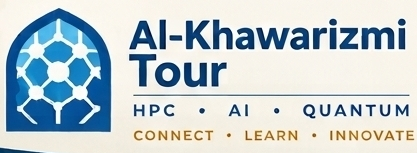
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 1 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Data Quality &amp; Preprocessing — Beijing Air Quality · Hands-on &amp; Week-1 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos used during the lecture (slide references in each heading) · Part B: the week-long <b>Air-Quality Data Challenge</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A11) | during the 2-hour lecture | each demo matches a slide of the deck / a card of the speaker script |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells, write your report, prepare your pitch |

**Dataset:** *Beijing Multi-Site Air Quality* — UCI Machine Learning Repository, dataset 501. Hourly PM2.5, PM10, SO2, NO2, CO, O3 (µg/m³) and TEMP, PRES, DEWP, RAIN, wind direction `wd`, wind speed `WSPM` at **12 stations**, **1 Mar 2013 – 28 Feb 2017**, **420,768 rows**, with real missing values (NA).
Reference: Zhang, S. et al. (2017) *Cautionary tales on air-quality improvement in Beijing*, Proc. R. Soc. A.

**Data access:** the notebook downloads the archive from UCI (≈ 8 MB) and caches it. If you already have the `PRSA_Data_*.csv` files, put them next to the notebook. Offline, a synthetic stand-in with the same columns is generated so the code still runs.

**Requirements:** Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, `scikit-learn ≥ 1.2`. Works in Jupyter, VS Code or Google Colab. Tip: on a laptop, run Part A first on `SAMPLE_STATIONS` (4 stations) and switch to all 12 for the challenge.

## 0 · Setup — set your team number first

In [3]:
TEAM_ID = 1218            # <-- your team number: it seeds YOUR version of the merged dataset
SEED = 1000 + TEAM_ID

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)
import sklearn; print("scikit-learn", sklearn.__version__, "| team", TEAM_ID)

scikit-learn 1.6.1 | team 1218


---
# Part A · Guided demos
## A1 · Load the 12 station files  *(slides 2 & 13)*

In [4]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    # Load from cache if already downloaded
    if os.path.exists(CACHE):
        print("Loading dataset from local cache...")
        return pd.read_csv(CACHE)

    # Download only once
    print("Downloading dataset from UCI...")
    frames = _csvs_from_zip(_download(URL))

    df = pd.concat(frames, ignore_index=True)

    # Save locally for future use
    df.to_csv(CACHE, index=False, compression="gzip")
    print(f"Dataset saved to {CACHE}")

    return df

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw.head()

Dataset saved to beijing_air_quality_raw.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## A2 · The scenario: a careless merge + an untouched final year  *(slides 27 & 32)*
* **Test year** = 1 Mar 2016 – 28 Feb 2017 (the real data, untouched) — used **only in Task 6**.
* **Training years** = 1 Mar 2013 – 29 Feb 2016 → turned into your team's *merged export* with realistic merge errors.

In [ ]:
SPLIT = pd.Timestamp("2016-03-01")
train_raw = raw[raw["datetime"] < SPLIT].reset_index(drop=True)
test_year = raw[raw["datetime"] >= SPLIT].reset_index(drop=True)
print(f"training years: {len(train_raw):,} rows | test year: {len(test_year):,} rows")

training years: 315,648 rows | test year: 105,120 rows


## A3 · Generate your team's merged export
The function reproduces problems of a careless multi-station merge. **Treat it as a black box during the challenge** — your job is to *discover* the problems from the data.

In [ ]:
def make_dirty(df, seed):
    r = np.random.default_rng(seed)
    d = df.drop(columns=["datetime"]).copy()
    n = len(d)
    st_unit, st_tz, st_stuck = r.choice(STATIONS, 3, replace=False)
    # 1) consistency: station-name variants and lower-case wind directions
    v = r.random(n)
    d.loc[v < .05, "station"] = d.loc[v < .05, "station"].str.upper()
    d.loc[(v >= .05) & (v < .10), "station"] = d.loc[(v >= .05) & (v < .10), "station"].str.lower() + " "
    w = r.random(n) < .02
    d.loc[w, "wd"] = d.loc[w, "wd"].str.lower()
    stn = d["station"].str.strip().str.title()
    # 2) accuracy: one station exported CO in mg/m3 during 2014
    m = (stn == st_unit) & (d["year"] == 2014)
    d.loc[m, "CO"] = d.loc[m, "CO"] / 1000
    # 3) timeliness: one station exported in UTC during 2015 (8 h behind Beijing time)
    m = (stn == st_tz) & (d["year"] == 2015)
    dt = pd.to_datetime(d.loc[m, ["year", "month", "day", "hour"]]) - pd.Timedelta(hours=8)
    d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: stuck PM2.5 sensor (flat lines), sentinel codes, PM2.5/PM10 column swap
    idx = np.flatnonzero((stn == st_stuck).values)
    for s0 in r.choice(idx[:-80], 8, replace=False):
        L = int(r.integers(24, 73)); rows = d.index[s0:s0 + L]
        d.loc[rows, "PM2.5"] = d.loc[rows[0], "PM2.5"]
    for c in ["TEMP", "PRES"]:
        d.loc[r.random(n) < .002, c] = -999
    sw = r.random(n) < .003
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) completeness: extra random logger drop-outs in NO2
    d.loc[r.random(n) < .03, "NO2"] = np.nan
    # 6) uniqueness: one station-month re-uploaded (slightly different O3) + scattered exact duplicates
    s_dup = r.choice(STATIONS); y_dup, m_dup = 2014, int(r.integers(1, 13))
    re = d[(stn == s_dup) & (d["year"] == y_dup) & (d["month"] == m_dup)].copy()
    re["O3"] = re["O3"] + 1
    d = pd.concat([d, re, d.sample(frac=.005, random_state=seed)], ignore_index=True)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

dirty = make_dirty(train_raw, SEED)
dirty.to_csv(f"beijing_merged_team{TEAM_ID}.csv.gz", index=False)
print(f"merged export: {dirty.shape[0]:,} rows -> beijing_merged_team{TEAM_ID}.csv.gz")
dirty.head()

merged export: 317,970 rows -> beijing_merged_team1218.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,3697,2013,8,2,0,25.0,21.0,3.0,4.0,500.0,24.0,21.8,996.3,19.9,0.0,N,0.0,Dingling
1,18974,2015,4,30,13,140.0,140.0,26.0,27.0,1200.0,189.0,27.6,1007.5,13.5,0.0,S,3.1,Shunyi
2,11598,2014,6,27,5,10.0,10.0,4.0,28.0,100.0,52.0,24.2,1001.5,15.4,0.0,NE,1.6,Aotizhongxin
3,14472,2014,10,24,23,308.0,334.0,6.0,163.0,3200.0,2.0,11.0,1006.2,11.0,0.0,NNE,0.0,Guanyuan
4,23908,2015,11,22,3,63.0,63.0,5.0,25.0,1000.0,7.0,0.3,1031.2,-1.0,0.0,E,0.8,Tiantan


## A4 · First look  *(slides 11, 13 & 14)*

In [ ]:
df = dirty.copy()
print("shape:", df.shape, "\n")
print(df.dtypes, "\n")
print("fraction missing:\n", df.isna().mean().round(4).sort_values(ascending=False), "\n")
print("duplicate station-hours:", df.duplicated(subset=KEY).sum())
print("station labels:", df["station"].nunique(), "distinct (expected 12)")

shape: (317970, 18) 

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object 

fraction missing:
 NO2        0.0596
CO         0.0573
O3         0.0322
SO2        0.0221
PM2.5      0.0202
PM10       0.0147
wd         0.0021
RAIN       0.0006
DEWP       0.0006
PRES       0.0006
WSPM       0.0006
TEMP       0.0006
year       0.0000
No         0.0000
day        0.0000
month      0.0000
hour       0.0000
station    0.0000
dtype: float64 

duplicate station-hours: 2330
station labels: 36 distinct (expected 12)


In [ ]:
# mean vs median per station -> skew; min / max -> impossible values
df.groupby(df["station"].str.strip().str.title())[["PM2.5", "CO", "TEMP", "PRES"]].agg(["mean", "median", "min", "max"]).round(1)

PM2.5                         CO                          TEMP  \
               mean median  min    max    mean  median    min      max  mean   
station                                                                        
Aotizhongxin   83.7   60.0  3.0  898.0  1272.4   900.0  100.0  10000.0  11.3   
Changping      72.5   47.0  2.0  882.0  1145.4   800.0  100.0  10000.0  11.4   
Dingling       66.8   41.0  3.0  881.0   907.6   600.0  100.0   9400.0  11.7   
Dongsi         84.7   60.0  3.0  737.0   810.3   500.0    0.1  10000.0  10.6   
Guanyuan       82.9   60.0  3.0  680.0  1289.9   900.0  100.0  10000.0  11.5   
Gucheng        83.9   61.0  2.0  770.0  1354.6  1000.0  100.0   9900.0  12.1   
Huairou        71.2   48.0  2.0  762.0  1034.6   800.0  100.0  10000.0  10.2   
Nongzhanguan   86.1   60.0  3.0  844.0  1335.1  1000.0  100.0  10000.0  11.7   
Shunyi         80.1   56.0  3.0  941.0  1187.4   900.0  100.0  10000.0  11.5   
Tiantan        82.8   60.0  3.0  821.0  1307.9  1000.0  100.0  10000.0  10.8   
Wanliu         85.2   61.0  3.0  957.0  1334.0   900.0  100.0  10000.0  11.2   
Wanshouxigong  84.9   61.0  3.0  999.0  1396.5  1000.0  100.0   9800.0  11.6   

                                     PRES                         
              median    min   max    mean  median    min     max  
station                                                           
Aotizhongxin    14.3 -999.0  40.5  1007.6  1011.2 -999.0  1042.0  
Changping       14.6 -999.0  41.4  1004.1  1007.5 -999.0  1036.5  
Dingling        14.6 -999.0  41.4  1004.1  1007.5 -999.0  1036.5  
Dongsi          13.8 -999.0  41.1  1008.8  1012.7 -999.0  1042.0  
Guanyuan        14.3 -999.0  40.5  1006.7  1011.2 -999.0  1042.0  
Gucheng         14.8 -999.0  41.6  1003.9  1008.6 -999.0  1038.1  
Huairou         13.4 -999.0  40.3  1003.4  1007.3 -999.0  1036.5  
Nongzhanguan    14.5 -999.0  41.1  1008.3  1012.2 -999.0  1042.0  
Shunyi          14.3 -999.0  40.6  1008.9  1012.7 -999.0  1042.8  
Tiantan         14.5 -999.0  41.1  1008.6  1012.3 -999.0  1042.0  
Wanliu          14.2 -999.0  40.5  1006.8  1010.8 -999.0  1040.3  
Wanshouxigong   14.6 -999.0  40.6  1007.9  1010.6 -999.0  1042.0

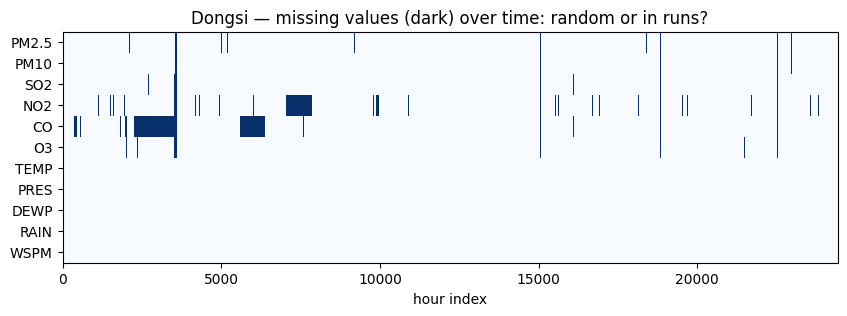

In [ ]:
# missing-value matrix for one station (rows = hours in time order)
one = df[df["station"] == "Dongsi"].sort_values(["year", "month", "day", "hour"])
plt.figure(figsize=(10, 3))
plt.imshow(one[POLLUTANTS + WEATHER].isna().values.T, aspect="auto", interpolation="nearest", cmap="Blues")
plt.yticks(range(len(POLLUTANTS + WEATHER)), POLLUTANTS + WEATHER); plt.xlabel("hour index"); plt.grid(False)
plt.title("Dongsi — missing values (dark) over time: random or in runs?"); plt.show()

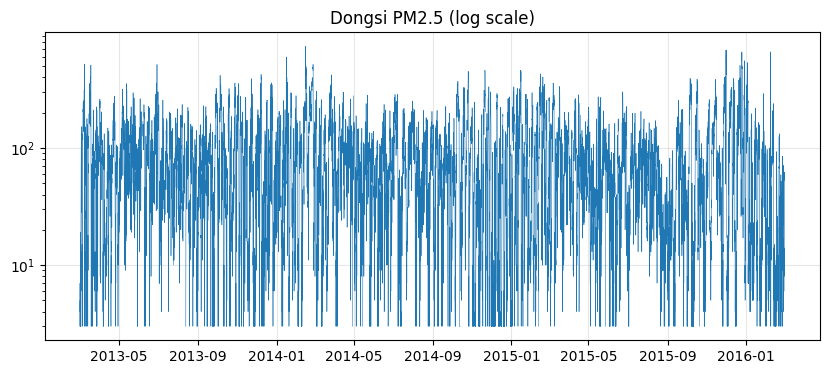

In [ ]:
# the single most useful plot: a time series per station
one_dt = pd.to_datetime(one[["year", "month", "day", "hour"]])
plt.plot(one_dt, one["PM2.5"], lw=.4); plt.yscale("log"); plt.title("Dongsi PM2.5 (log scale)"); plt.show()

## A5 · Consistency: canonical labels  *(slide 21)*

In [ ]:
print(df["station"].value_counts().head(15))
canon = df["station"].str.strip().str.title()
print("\nafter strip + title:", canon.nunique(), "stations")
print("wind directions:", sorted(df["wd"].dropna().unique()))

station
Dongsi           24423
Wanliu           23878
Changping        23845
Tiantan          23840
Guanyuan         23806
Huairou          23782
Gucheng          23780
Dingling         23773
Aotizhongxin     23763
Shunyi           23698
Nongzhanguan     23692
Wanshouxigong    23674
DONGSI            1420
shunyi            1386
WANSHOUXIGONG     1382
Name: count, dtype: int64

after strip + title: 12 stations
wind directions: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW', 'e', 'ene', 'ese', 'n', 'ne', 'nne', 'nnw', 'nw', 's', 'se', 'sse', 'ssw', 'sw', 'w', 'wnw', 'wsw']


## A6 · Outliers, stuck sensors and physics checks  *(slides 19 & 20)*

In [ ]:
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

,rows
PM2.5 > PM10 (impossible),22063
negative concentrations,0
sentinel -999 codes,1288
PRES outside 950-1060 hPa,643


In [ ]:
def hampel_flags(s, window=25, k=3.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med).abs() > k * 1.4826 * mad

def stuck_flags(s, hours=12):
    return s.rolling(hours).std() == 0

res = {}
for st, g in df.assign(station=canon).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()), "stuck >= 12 h": int(stuck_flags(g["PM2.5"]).sum())}
pd.DataFrame(res).T.sort_values("stuck >= 12 h", ascending=False)

,Hampel spikes,stuck >= 12 h
Nongzhanguan,1173,291
Dongsi,1415,110
Wanshouxigong,1120,23
Huairou,1356,19
Gucheng,1247,2
Aotizhongxin,1182,1
Dingling,1518,0
Changping,1214,0
Guanyuan,1117,0
Shunyi,1177,0


## A7 · Imputation study — single hours vs 24-hour gaps  *(slide 18)*
We hide values we **know** (clean reference = the original training years, demo only) and measure the RMSE of each imputer.

In [ ]:
from sklearn.impute import KNNImputer
piv = train_raw.pivot_table(index="datetime", columns="station", values="NO2")   # hours x stations
target_st = "Dongsi"
truth = piv[target_st]
known = np.flatnonzero(truth.notna().values)

def make_mask(kind):
    m = np.zeros(len(truth), bool)
    if kind == "single hours":
        m[rng.choice(known, len(known) // 10, replace=False)] = True
    else:                                                    # 24-h blocks
        for s0 in rng.choice(known[:-30], 150, replace=False):
            m[s0:s0 + 24] = True
        m &= truth.notna().values
    return m

def evaluate(mask):
    s = truth.mask(mask)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.Series(KNNImputer(n_neighbors=5).fit_transform(piv.assign(**{target_st: s}))[:, list(piv.columns).index(target_st)], index=s.index),
    }
    return {k: np.sqrt(np.mean((v.fillna(s.mean()).values[mask] - truth.values[mask]) ** 2)) for k, v in cand.items()}

t0 = time.perf_counter()
study = pd.DataFrame({kind: evaluate(make_mask(kind)) for kind in ["single hours", "24-h blocks"]}).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE of NO2 in µg/m³ — lower is better")
study

(23.2 s)  RMSE of NO2 in µg/m³ — lower is better


,single hours,24-h blocks
mean,33.72,33.66
median,34.29,34.50
time interpolation,8.00,26.83
neighbour stations,14.53,13.95
KNN across stations,9.65,11.59


## A8 · Skewness and transformations  *(slides 12 & 25)*

skewness raw:
 PM2.5    1.93
SO2      2.74
CO       2.45
NO2      1.03
O3       1.75
WSPM     1.67
dtype: float64

skewness after log1p:
 PM2.5   -0.33
SO2      0.42
CO      -0.00
NO2     -0.72
O3      -0.59
WSPM     0.29
dtype: float64


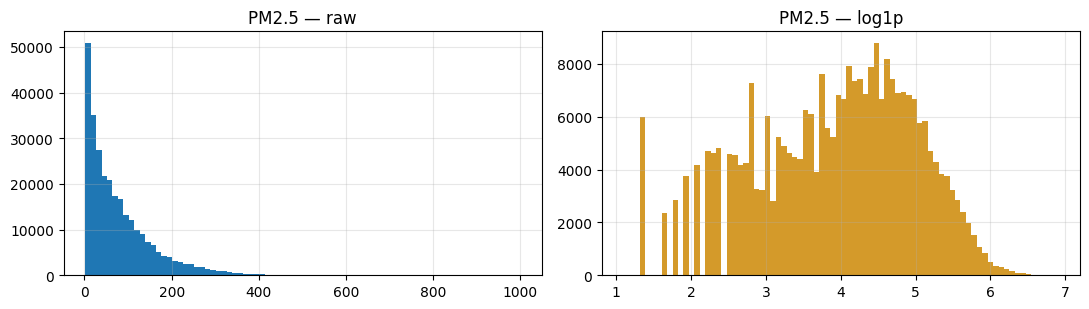

In [ ]:
from sklearn.preprocessing import PowerTransformer
vals = train_raw[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
print("skewness raw:\n", vals.skew().round(2))
print("\nskewness after log1p:\n", np.log1p(vals).skew().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals["PM2.5"], bins=80); ax[0].set_title("PM2.5 — raw")
ax[1].hist(np.log1p(vals["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 — log1p")
plt.tight_layout(); plt.show()

## A9 · Multicollinearity — VIF  *(slide 22)*

In [ ]:
def vif(frame):
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for c in X.columns:
        Aa = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(Aa, X[c].values, rcond=None)
        resid = X[c].values - Aa @ coef
        out[c] = 1 / max(1 - (1 - (resid ** 2).sum() / ((X[c] - X[c].mean()) ** 2).sum()), 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

vif(train_raw[["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]].dropna().sample(50_000, random_state=0))

,VIF
TEMP,7.83
DEWP,5.75
PRES,3.14
NO2,2.62
CO,2.52
O3,2.23
SO2,1.83
WSPM,1.60


## A10 · Leakage demo — random split vs time split  *(slides 27 & 28)*
Same model, same data, two ways of splitting. The random split lets near-identical neighbouring hours sit on both sides.

In [ ]:
def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

def make_pipeline(model):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

ref = add_features(train_raw.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
ref = ref.iloc[::3]                                   # every 3rd hour keeps the demo fast
X_ref, y_ref = ref[NUM_FEATS + CAT_FEATS], ref[TARGET]
hgb = make_pipeline(HistGradientBoostingRegressor(max_iter=200, random_state=0))
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(hgb, X_ref, y_ref, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:16s} CV RMSE = {-s.mean():6.2f} ± {s.std():.2f} µg/m³")

random KFold     CV RMSE =  29.70 ± 0.19 µg/m³
TimeSeriesSplit  CV RMSE =  43.11 ± 11.33 µg/m³


## A11 · Template: a leak-free, time-aware pipeline  *(slide 29)*
`make_pipeline` above is the template you adapt in Task 5. Everything that *learns* (imputers, scalers, encoders) lives **inside** it, so it is re-fitted in every fold.

---
# Part B · Week-1 Team Challenge — *The Air-Quality Data Challenge*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The city’s environmental agency merged the exports of its <b>12 monitoring stations</b> (1 Mar 2013 – 29 Feb 2016) for an AI project. On top of the real gaps, the merge introduced errors. Your file <code>beijing_merged_team&lt;N&gt;.csv.gz</code> (created in A3) is your team’s version. <br><b>Goal:</b> deliver a documented, leak-free pipeline for a <b>virtual PM2.5 sensor</b> — estimate PM2.5 from gases, weather, time and station, <b>without PM10</b> (same instrument, down at the same time) — and <b>prove with numbers</b> how much your data work improves it on the untouched test year.</div>

| # | Task | Points |
|---|---|---|
| 1 | Data-quality audit (six dimensions, gap lengths, missingness by station) | 15 |
| 2 | Consistency, validity & timeliness fixes | 15 |
| 3 | Imputation study (≥ 3 imputers incl. one time-aware) | 15 |
| 4 | Outliers: stuck sensors & spikes vs real episodes; transformations | 10 |
| 5 | Leak-free pipeline + `TimeSeriesSplit` CV | 15 |
| 6 | Impact study on the test year | 20 |
| ★ | HPC bonus: parallel per-station cleaning | +10 |
|   | 1-page report + 5-min pitch | 10 |

**Rules:** `test_year` only in Task 6 · justify every decision in one line · keep `SEED` fixed · start from `beijing_merged_team<N>.csv.gz`, not from `train_raw`.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–5 · Day 5 Task 6 (+ bonus) · Days 6–7 report & pitch.

**Hint — what kinds of problems to look for:** label variants, a unit mix-up, a time-zone shift, re-uploaded data, stuck sensors, sentinel codes, physically impossible values, extra drop-outs. *Which station, which column, which period? That is for you to find.*

## Task 1 · Data-quality audit (15 pts)

Missing per Column


,Total Rows,Missing Count,Missing %
NO2,317970,18936,5.96
CO,317970,18215,5.73
O3,317970,10245,3.22
SO2,317970,7041,2.21
PM2.5,317970,6423,2.02
PM10,317970,4662,1.47
TEMP,317970,825,0.26
PRES,317970,823,0.26
wd,317970,679,0.21
DEWP,317970,185,0.06


Missing per Station


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM
canon_station,,,,,,,,,,,,
Aotizhongxin,2.84,2.30,3.02,6.05,6.18,5.54,0.21,0.20,0.01,0.01,0.04,0.01
Changping,2.51,1.84,1.85,5.03,5.19,1.87,0.34,0.31,0.12,0.13,0.28,0.12
Dingling,1.88,1.85,2.01,6.83,6.70,2.86,0.31,0.31,0.12,0.13,0.28,0.12
Dongsi,1.46,0.98,1.38,7.73,10.64,1.31,0.25,0.21,0.01,0.01,0.03,0.01
Guanyuan,1.61,1.10,1.42,5.15,5.83,4.04,0.19,0.25,0.01,0.01,0.04,0.01
Gucheng,1.85,1.06,1.57,4.92,4.83,2.39,0.30,0.37,0.13,0.10,0.45,0.12
Huairou,3.11,2.46,3.18,7.68,4.58,3.72,0.33,0.33,0.13,0.14,0.54,0.14
Nongzhanguan,1.84,1.25,1.28,4.87,3.68,1.48,0.19,0.22,0.01,0.01,0.03,0.01
Shunyi,2.22,1.05,3.30,6.41,6.67,2.19,0.29,0.33,0.14,0.12,0.75,0.12


Sentinel Values Found


,0
TEMP,645
PRES,643


... (6 outputs left out)

PM2.5   PM10    SO2    NO2      CO     O3
canon_station year                                           
Aotizhongxin  2013   62.0   97.0  14.00  60.00   900.0  34.00
              2014   69.0   98.0  10.00  60.00   900.0  32.00
              2015   55.0   87.0   7.00  53.00   900.0  50.00
              2016   21.0   44.0  13.00  34.00   800.0  46.00
Changping     2013   52.0   74.0  10.93  35.00   800.0  48.00
              2014   53.0   84.0   9.00  38.00   800.0  50.00
              2015   45.0   68.0   4.00  34.00   700.0  47.00
              2016   19.0   44.0   9.00  42.00   700.0  43.00
Dingling      2013   43.0   58.0   6.00  21.97   700.0  56.00
              2014   47.0   68.0   6.00  19.00   600.0  62.00
              2015   39.0   59.0   6.00  18.00   600.0  65.00
              2016   16.0   39.0   8.00  10.00   400.0  66.00
Dongsi        2013   66.0   91.0  15.00  52.15  1100.0  47.00
              2014   63.0   94.0  13.00  51.00     1.1  43.00
              2015   58.0   85.0   8.00  42.00   900.0  43.00
              2016   22.0   47.0  10.00  36.00   700.0  40.00
Guanyuan      2013   62.0   93.0  12.00  53.00   900.0  44.00
              2014   67.0   97.0  10.00  58.00  1000.0  39.00
              2015   56.0   84.0   6.00  46.00   900.0  41.00
              2016   22.0   44.0  12.00  44.00   800.0  31.00
Gucheng       2013   62.0  100.0   8.00  58.00  1000.0  45.00
              2014   68.0  118.0   9.00  58.00  1000.0  44.00
              2015   56.0   91.0   5.00  43.00   900.0  48.00
              2016   30.0   55.0  16.00  31.00  1000.0  44.00
Huairou       2013   48.0   74.0   7.00  30.00   800.0  51.00
              2014   54.0   81.0   6.00  31.00   900.0  57.00
              2015   46.0   65.0   3.00  21.00   700.0  49.00
              2016   23.0   35.0   5.00  21.00   700.0  29.00
Nongzhanguan  2013   62.0   87.0  13.00  54.00  1000.0  42.00
              2014   67.0  103.0  11.00  57.00  1000.0  43.00
              2015   56.0   81.0   8.00  48.00   900.0  48.00
              2016   22.0   39.0  11.00  44.00   700.0  44.00
Shunyi        2013   57.0   80.0   6.85  35.00  1000.0  46.27
              2014   62.0   92.0   7.00  40.00   900.0  43.00
              2015   54.0   74.0   3.00  37.00   800.0  39.00
              2016   23.0   34.0   7.00  29.00   600.0  42.00
Tiantan       2013   63.5   93.0   9.00  49.00  1000.0  37.00
              2014   66.0   96.0   9.00  50.00  1000.0  39.00
              2015   55.0   79.0   6.00  44.00   900.0  44.00
              2016   25.0   50.0   9.00  45.00   800.0  40.00
Wanliu        2013   70.0   98.0  15.00  65.49  1000.0  35.00
              2014   66.0  112.0  13.00  70.00   900.0  24.00
              2015   54.0   83.0   8.00  51.00   900.0  32.00
              2016   23.0   41.5  14.00  50.00  1000.0  31.00
Wanshouxigong 2013   65.0   95.0  11.00  52.00  1200.0  41.00
              2014   68.0  105.0   9.00  55.00  1100.0  41.00
              2015   56.0   86.0   6.00  44.00   900.0  46.00
              2016   28.0   47.5  13.00  39.50   900.0  36.00

,canon_station,year,hour,TEMP,O3
0,Aotizhongxin,2013,0,12.583333,31.304314
1,Aotizhongxin,2013,1,12.104531,28.026862
2,Aotizhongxin,2013,2,11.816938,25.393356
3,Aotizhongxin,2013,3,11.517377,21.831163
4,Aotizhongxin,2013,4,11.269055,19.014821


,canon_station,year,hour,TEMP,Variable,O3
0,Aotizhongxin,2013,14,20.712131,TEMP,NaN
1,Aotizhongxin,2014,14,18.950949,TEMP,NaN
2,Aotizhongxin,2015,15,17.771662,TEMP,NaN
3,Aotizhongxin,2016,15,2.518333,TEMP,NaN
4,Changping,2013,14,20.557329,TEMP,NaN
...,...,...,...,...,...,...
91,Wanliu,2016,14,NaN,O3,59.852459
92,Wanshouxigong,2013,16,NaN,O3,102.654665
93,Wanshouxigong,2014,15,NaN,O3,108.286932
94,Wanshouxigong,2015,16,NaN,O3,105.614958


Variable,canon_station,year,O3 Peak Hour,TEMP Peak Hour
0,Aotizhongxin,2013,16,14
1,Aotizhongxin,2014,16,14
2,Aotizhongxin,2015,16,15
3,Aotizhongxin,2016,14,15
4,Changping,2013,16,14
5,Changping,2014,16,14
6,Changping,2015,16,15
7,Changping,2016,15,15
8,Dingling,2013,16,14
9,Dingling,2014,16,14


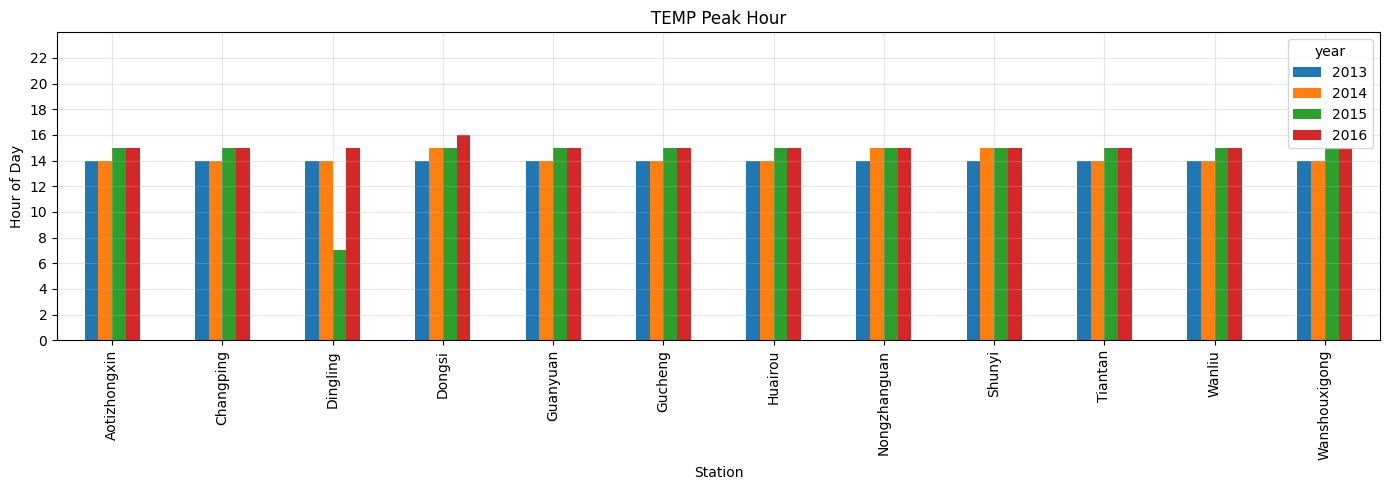

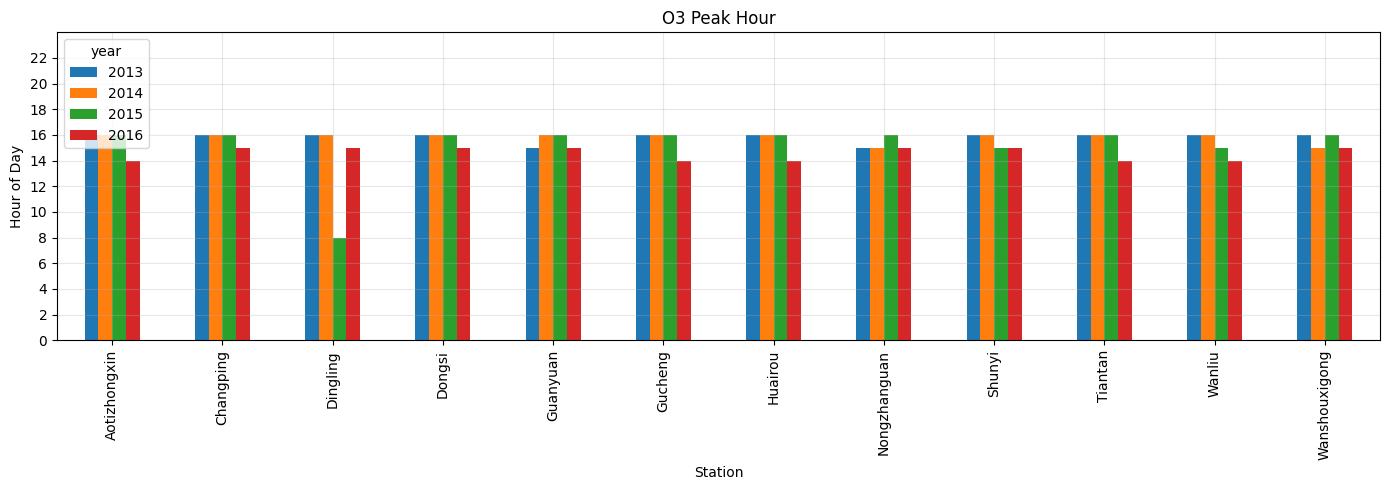

Station Labels


,canon_station,station,Count
1,Aotizhongxin,Aotizhongxin,23763
2,Aotizhongxin,aotizhongxin,1364
0,Aotizhongxin,AOTIZHONGXIN,1302
4,Changping,Changping,23845
5,Changping,changping,1327
3,Changping,CHANGPING,1279
7,Dingling,Dingling,23773
8,Dingling,dingling,1351
6,Dingling,DINGLING,1307
10,Dongsi,Dongsi,24423


Wind Direction Labels


,canon_wd,wd,Count
0,E,E,23028
1,E,e,487
2,ENE,ENE,25991
3,ENE,ene,566
4,ESE,ESE,18120
5,ESE,ese,382
6,N,N,23888
7,N,n,505
8,NE,NE,29728
9,NE,ne,595


In [ ]:
df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")

df_audit = df.copy()

sentinel_counts = df_audit[["TEMP", "PRES"]].eq(-999).sum()

df_audit[["TEMP", "PRES"]] = (
    df_audit[["TEMP", "PRES"]].replace(-999, np.nan)
)

df_audit["canon_station"] = (
    df_audit["station"]
    .str.strip()
    .str.title()
)

columns = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES",
    "DEWP", "RAIN", "wd", "WSPM"
]

original_columns = df.columns

missing_per_column = pd.DataFrame({
    "Total Rows": len(df_audit),
    "Missing Count": df_audit[original_columns].isna().sum(),
    "Missing %": df_audit[original_columns].isna().mean() * 100
})

missing_per_column = (
    missing_per_column
    .sort_values("Missing %", ascending=False)
    .round(2)
)

# 3. Missing per station
missing_per_station = (
    df_audit
    .groupby("canon_station")[columns]
    .apply(lambda group: group.isna().mean() * 100)
    .round(2)
)

# 4. Display results
print("Missing per Column")
display(missing_per_column)

print("Missing per Station")
display(missing_per_station)

print("Sentinel Values Found")
display(sentinel_counts)

# TODO 1b uniqueness: duplicate station-hours (KEY); are duplicates identical or slightly different?
audit_key = [
    "canon_station",
    "year",
    "month",
    "day",
    "hour"
]

audit_key = [
    "canon_station",
    "year", "month", "day", "hour"
]

duplicates = df_audit[
    df_audit.duplicated(subset=audit_key, keep=False)
].copy()

print("Duplicate rows:", len(duplicates))
print(
    "Duplicate station-hours:",
    duplicates[audit_key].drop_duplicates().shape[0]
)

measurements = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES",
    "DEWP", "RAIN", "wd", "WSPM"
]

duplicate_groups = duplicates.groupby(
    audit_key,
    dropna=False
)

duplicate_report = duplicate_groups[measurements].nunique(
    dropna=False
)

# A group is conflicting if any measurement differs
conflicting = duplicate_report.gt(1).any(axis=1)

print("Identical groups:", (~conflicting).sum())
print("Conflicting groups:", conflicting.sum())

# TODO 1c validity: PM2.5 > PM10, negative values, -999 codes, implausible PRES / TEMP
pm_invalid = df["PM2.5"] > df["PM10"]

pm_report = (
    df.assign(
        canon_station=df["station"].str.strip().str.title(),
        pm_invalid=pm_invalid
    )
    .groupby("canon_station")["pm_invalid"]
    .agg(
        Invalid_Count="sum",
        Total_Rows="count",
        Invalid_Percentage="mean"
    )
)

pm_report["Invalid_Percentage"] *= 100

display(pm_report.round(2))

pollutants = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3"
]

negative_report = (
    df[pollutants] < 0
).sum().to_frame("Negative_Count")

display(negative_report)

measurements = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES",
    "DEWP", "RAIN", "WSPM"
]

sentinel_report = (
    df[measurements].eq(-999)
    .sum()
    .to_frame("Sentinel_Count")
)

display(sentinel_report)

valid_ranges = {
    "TEMP": (-40, 50),
    "PRES": (850, 1100)
}

range_report = []

for column, (minimum, maximum) in valid_ranges.items():

    # Exclude missing values from the validity check
    invalid = (
        df[column].notna()
        & ~df[column].between(minimum, maximum)
    )

    range_report.append({
        "Column": column,
        "Minimum Allowed": minimum,
        "Maximum Allowed": maximum,
        "Invalid Count": invalid.sum(),
        "Invalid %": invalid.mean() * 100
    })

range_report = pd.DataFrame(range_report)

display(range_report.round(2))

validity_summary = pd.DataFrame([
    {
        "Check": "PM2.5 > PM10",
        "Count": pm_invalid.sum()
    },
    {
        "Check": "Negative pollutants",
        "Count": (df[pollutants] < 0).sum().sum()
    },
    {
        "Check": "TEMP = -999",
        "Count": df["TEMP"].eq(-999).sum()
    },
    {
        "Check": "PRES = -999",
        "Count": df["PRES"].eq(-999).sum()
    }
])

validity_summary["Percentage"] = (
    validity_summary["Count"] / len(df) * 100
)

display(validity_summary.round(2))
# TODO 1d accuracy: station medians of each pollutant on a log scale — any station x1000 off? which years?
pollutants = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3"
]

accuracy_df = df.copy()

accuracy_df["canon_station"] = (
    accuracy_df["station"]
    .str.strip()
    .str.title()
)

station_year_medians = (
    accuracy_df
    .groupby(["canon_station", "year"])[pollutants]
    .median()
)

display(station_year_medians.round(2))
# TODO 1e timeliness: hour of the mean daily TEMP / O3 peak per station and year — any station shifted?
hourly_means = (
    df_audit
    .groupby(["canon_station", "year", "hour"])[["TEMP", "O3"]]
    .mean()
    .reset_index()
)

display(hourly_means.head())

peak_report = []

for variable in ["TEMP", "O3"]:

    peak_indices = (
        hourly_means
        .groupby(["canon_station", "year"])[variable]
        .idxmax()
        .dropna()
    )

    peaks = hourly_means.loc[
        peak_indices,
        ["canon_station", "year", "hour", variable]
    ].copy()

    peaks["Variable"] = variable

    peak_report.append(peaks)

peak_report = pd.concat(
    peak_report,
    ignore_index=True
)

display(peak_report)

timeliness_report = (
    peak_report
    .pivot(
        index=["canon_station", "year"],
        columns="Variable",
        values="hour"
    )
    .rename(columns={
        "TEMP": "TEMP Peak Hour",
        "O3": "O3 Peak Hour"
    })
    .reset_index()
)

display(timeliness_report)

import matplotlib.pyplot as plt

for variable in ["TEMP Peak Hour", "O3 Peak Hour"]:

    chart = timeliness_report.pivot(
        index="canon_station",
        columns="year",
        values=variable
    )

    ax = chart.plot(
        kind="bar",
        figsize=(14, 5)
    )

    ax.set_title(variable)
    ax.set_ylabel("Hour of Day")
    ax.set_xlabel("Station")
    ax.set_ylim(0, 24)
    ax.set_yticks(range(0, 24, 2))

    plt.tight_layout()
    plt.show()

# TODO 1f consistency: raw station and wd labels
# TODO 1f consistency: raw station and wd labels

# 1. Prepare canonical labels
consistency_df = df.copy()

consistency_df["canon_station"] = (
    consistency_df["station"]
    .str.strip()
    .str.title()
)

consistency_df["canon_wd"] = (
    consistency_df["wd"]
    .str.strip()
    .str.upper()
)

# 2. Station label report
station_labels = (
    consistency_df
    .groupby(["canon_station", "station"], dropna=False)
    .size()
    .reset_index(name="Count")
    .sort_values(["canon_station", "Count"],
                 ascending=[True, False])
)

print("Station Labels")
display(station_labels)

# 3. Wind direction label report
wind_labels = (
    consistency_df
    .groupby(["canon_wd", "wd"], dropna=False)
    .size()
    .reset_index(name="Count")
    .sort_values(["canon_wd", "Count"],
                 ascending=[True, False])
)

print("Wind Direction Labels")
display(wind_labels)

In [ ]:
issue_log = pd.DataFrame(columns=[
    "dimension", "station", "column", "period",
    "problem", "rows affected", "fix", "justification"
])

# Completeness — missing NO2
issue_log.loc[len(issue_log)] = [
    "completeness",
    "all",
    "NO2",
    "all",
    "Missing measurements (NaN)",
    int(df["NO2"].isna().sum()),
    "Impute according to gap length",
    "Missing NO2 readings reduce data completeness"
]

# Validity — TEMP sentinel
issue_log.loc[len(issue_log)] = [
    "validity",
    "all",
    "TEMP",
    "all",
    "-999 sentinel values",
    int(df["TEMP"].eq(-999).sum()),
    "Convert -999 to NaN",
    "Not a plausible temperature measurement"
]

# Validity — PRES sentinel
issue_log.loc[len(issue_log)] = [
    "validity",
    "all",
    "PRES",
    "all",
    "-999 sentinel values",
    int(df["PRES"].eq(-999).sum()),
    "Convert -999 to NaN",
    "Not a plausible atmospheric pressure"
]

# Validity — PM2.5 > PM10
issue_log.loc[len(issue_log)] = [
    "validity",
    "all",
    "PM2.5 / PM10",
    "all",
    "PM2.5 exceeds PM10",
    int((df["PM2.5"] > df["PM10"]).sum()),
    "Investigate suspected swapped readings",
    "Violates expected particulate concentration relationship"
]

# Consistency — station labels
canon_station = df["station"].str.strip().str.title()

issue_log.loc[len(issue_log)] = [
    "consistency",
    "all",
    "station",
    "all",
    "Inconsistent station labels",
    int((df["station"].notna() & df["station"].ne(canon_station)).sum()),
    "Strip whitespace and standardize case",
    "Multiple raw labels refer to the same monitoring station"
]

display(issue_log)

,dimension,station,column,period,problem,rows affected,fix,justification
0,completeness,all,NO2,all,Missing measurements (NaN),18936,Impute according to gap length,Missing NO2 readings reduce data completeness
1,validity,all,TEMP,all,-999 sentinel values,645,Convert -999 to NaN,Not a plausible temperature measurement
2,validity,all,PRES,all,-999 sentinel values,643,Convert -999 to NaN,Not a plausible atmospheric pressure
3,validity,all,PM2.5 / PM10,all,PM2.5 exceeds PM10,22063,Investigate suspected swapped readings,Violates expected particulate concentration re...
4,consistency,all,station,all,Inconsistent station labels,32016,Strip whitespace and standardize case,Multiple raw labels refer to the same monitori...


## Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write **one function** `clean_basic(df)` you could apply to next month's export. It should at least: canonicalise `station` and `wd`; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values to NaN (or repair the swap); flag stuck-sensor runs as NaN; resolve duplicate station-hours; build `datetime`; sort by station and time.

In [ ]:
TEAM_ID = 1218
df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")

In [ ]:
import os
import numpy as np
import pandas as pd

TEAM_ID = 1218
file_name = f"beijing_merged_team{TEAM_ID}.csv.gz"

VALID_WD = [
    "N", "NNE", "NE", "ENE",
    "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW",
    "W", "WNW", "NW", "NNW"
]


def clean_basic(d, swap_pm=False, stuck_hours=24):
    d = d.copy()

    # 1. Standardize labels while preserving missing values
    d["station"] = (
        d["station"].astype("string").str.strip().str.title()
    )
    d["wd"] = (
        d["wd"].astype("string").str.strip().str.upper()
    )

    d.loc[~d["station"].isin(STATIONS), "station"] = pd.NA
    d.loc[~d["wd"].isin(VALID_WD), "wd"] = pd.NA

    # 2. Sentinel codes and invalid measurements
    pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
    weather = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

    for col in pollutants + weather:
        d[col] = pd.to_numeric(d[col], errors="coerce")
        d.loc[d[col].eq(-999), col] = np.nan

    for col in pollutants + ["RAIN", "WSPM"]:
        d.loc[d[col] < 0, col] = np.nan

    d.loc[~d["TEMP"].between(-40, 50), "TEMP"] = np.nan
    d.loc[~d["PRES"].between(850, 1100), "PRES"] = np.nan
    d.loc[d["DEWP"] < -50, "DEWP"] = np.nan

    # 3. Confirmed CO unit issue: Dongsi, 2014
    # The median check avoids multiplying already-corrected data again.
    mask_co = (
        d["station"].eq("Dongsi")
        & d["year"].eq(2014)
    ).fillna(False)

    co_median = d.loc[mask_co, "CO"].median()

    if pd.notna(co_median) and 0 < co_median < 20:
        d.loc[mask_co, "CO"] *= 1000

    # 4. Build datetime
    d["datetime"] = pd.to_datetime(
        d[["year", "month", "day", "hour"]],
        errors="coerce"
    )

    # This export's No column is a sequential hourly index.
    # Infer its origin from the dominant agreement across the export.
    if "No" not in d.columns:
        raise ValueError(
            "No is required to verify the timezone repair."
        )

    sequence = pd.to_numeric(d["No"], errors="coerce")
    valid_sequence = (
        sequence.notna()
        & sequence.ge(1)
        & sequence.mod(1).eq(0)
        & d["datetime"].notna()
    )

    offsets = pd.to_timedelta(
        (sequence - 1).where(valid_sequence), unit="h"
    )
    origins = (d["datetime"] - offsets).dropna()

    if origins.empty:
        raise ValueError("Cannot verify the hourly No sequence.")

    origin = origins.mode().iloc[0]

    if origins.eq(origin).mean() < 0.90:
        raise ValueError(
            "No does not consistently match the hourly timestamps. "
            "Verify the export before repairing timezone offsets."
        )

    expected_datetime = origin + offsets

    # Use expected year, so shifted New Year's hours are included.
    mask_tz = (
        d["station"].eq("Dingling")
        & expected_datetime.dt.year.eq(2015)
        & (expected_datetime - d["datetime"]).eq(
            pd.Timedelta(hours=8)
        )
    ).fillna(False)

    d.loc[mask_tz, "datetime"] = expected_datetime[mask_tz]

    # Discard rows with unusable station/time keys
    d = d.dropna(subset=["station", "datetime"]).copy()

    for col in ["year", "month", "day", "hour"]:
        d[col] = getattr(d["datetime"].dt, col)

    # 5. Resolve duplicates BEFORE detecting constant runs
    # Prefer the row with the most available measurements.
    d["_available"] = d[pollutants + weather + ["wd"]].notna().sum(axis=1)

    d = (
        d.sort_values(
            ["station", "datetime", "_available"],
            ascending=[True, True, False],
            kind="stable"
        )
        .drop_duplicates(["station", "datetime"], keep="first")
        .drop(columns="_available")
        .reset_index(drop=True)
    )

    # 6. Flag PM inversions; swapping requires an explicit choice
    suspected_swap = (
        d["PM2.5"].notna()
        & d["PM10"].notna()
        & d["PM2.5"].gt(d["PM10"])
    )

    d["PM_swap_suspect"] = suspected_swap.astype("int8")

    if swap_pm:
        d.loc[suspected_swap, ["PM2.5", "PM10"]] = (
            d.loc[suspected_swap, ["PM10", "PM2.5"]].to_numpy()
        )

    # 7. Detect constant readings over consecutive hourly records
    d["PM2.5_stuck_suspect"] = np.int8(0)

    for _, group in d.groupby("station", sort=False):
        values = group["PM2.5"]

        new_run = (
            values.ne(values.shift())
            | group["datetime"].diff().ne(
                pd.Timedelta(hours=1)
            )
        )

        run_id = new_run.cumsum()
        run_lengths = run_id.groupby(run_id).transform("size")

        stuck = values.notna() & run_lengths.ge(stuck_hours)
        stuck_idx = group.index[stuck]

        d.loc[stuck_idx, "PM2.5_stuck_suspect"] = 1
        d.loc[stuck_idx, "PM2.5"] = np.nan

    return (
        d.sort_values(["station", "datetime"])
        .reset_index(drop=True)
    )


STATIONS = [
    "Aotizhongxin", "Changping", "Dingling", "Dongsi",
    "Guanyuan", "Gucheng", "Huairou", "Nongzhanguan",
    "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"
]

if not os.path.exists(file_name):
    raise FileNotFoundError(
        f"File not found: {file_name}\n"
        f"Current folder: {os.getcwd()}"
    )

df = pd.read_csv(file_name)

df_clean = clean_basic(
    df,
    swap_pm=False,
    stuck_hours=24
)

assert not df_clean.duplicated(["station", "datetime"]).any()

print(
    f"{len(df):,} -> {len(df_clean):,} rows | "
    f"stations: {df_clean['station'].nunique()}"
)
print("PM inversions flagged:", df_clean["PM_swap_suspect"].sum())
print("Constant-run labels removed:", df_clean["PM2.5_stuck_suspect"].sum())

317,970 -> 315,648 rows | stations: 12
PM inversions flagged: 21955
Constant-run labels removed: 414


In [ ]:
print("Rows:", len(df_clean))
print("Stations:", df_clean["station"].nunique())
print("Duplicate station-hours:", df_clean.duplicated(["station", "datetime"]).sum())

print("\nSentinel values:")
print(df_clean[["TEMP", "PRES"]].eq(-999).sum())

print("\nInvalid PM2.5 > PM10:")
print(
    (
        df_clean["PM2.5"].notna() &
        df_clean["PM10"].notna() &
        (df_clean["PM2.5"] > df_clean["PM10"])
    ).sum()
)

print("\nNegative pollutants:")
print(
    (df_clean[
        ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
    ] < 0).sum()
)

print("\nTEMP outside range:")
print(
    (
        df_clean["TEMP"].notna() &
        ~df_clean["TEMP"].between(-40, 50)
    ).sum()
)

print("\nPRES outside range:")
print(
    (
        df_clean["PRES"].notna() &
        ~df_clean["PRES"].between(850, 1100)
    ).sum()
)

print("\nStation labels:")
print(sorted(df_clean["station"].dropna().unique()))

print("\nWind direction labels:")
print(sorted(df_clean["wd"].dropna().unique()))

Rows: 315648
Stations: 12
Duplicate station-hours: 0

Sentinel values:
TEMP    0
PRES    0
dtype: int64

Invalid PM2.5 > PM10:
21744

Negative pollutants:
PM2.5    0
PM10     0
SO2      0
NO2      0
CO       0
O3       0
dtype: int64

TEMP outside range:
0

PRES outside range:
0

Station labels:
['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']

Wind direction labels:
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


In [ ]:
print("Missing PM2.5:", df_clean["PM2.5"].isna().sum())
print("Missing CO:", df_clean["CO"].isna().sum())
print("Missing NO2:", df_clean["NO2"].isna().sum())

Missing PM2.5: 6782
Missing CO: 18106
Missing NO2: 18801


## Task 3 · Imputation study (15 pts)
Using **your cleaned data**, extend A7: compare ≥ 3 imputers (at least one time-aware, e.g. limited interpolation, neighbour-station, seasonal-hourly profile) for **two** pollutants, with both single-hour and 24-h masks. Choose a strategy per gap length and justify it.

Finished: PM2.5 / Dongsi
Finished: PM2.5 / Dingling
Finished: PM2.5 / Nongzhanguan
Finished: NO2 / Dongsi
Finished: NO2 / Dingling
Finished: NO2 / Nongzhanguan

Completed in 9.9 seconds.

PM2.5: RMSE including global-mean fallback


gap_h,1,3,6,24
imputer,,,,
KNN similar hours,18.92 ± 5.38,21.56 ± 7.07,19.07 ± 4.71,22.46 ± 7.07
global mean,73.37 ± 11.89,79.45 ± 20.23,70.21 ± 9.37,85.96 ± 18.53
interpolation <=24h,9.97 ± 2.12,17.49 ± 4.08,23.12 ± 6.35,46.32 ± 9.51
interpolation <=3h,9.97 ± 2.12,17.49 ± 4.08,70.21 ± 9.37,85.96 ± 18.53
neighbour stations + bias,23.78 ± 7.65,27.00 ± 6.74,25.00 ± 5.66,27.71 ± 7.89
seasonal month-hour,73.11 ± 10.47,77.46 ± 18.78,68.91 ± 8.70,84.66 ± 16.60


Coverage before fallback (%)


gap_h,1,3,6,24
imputer,,,,
KNN similar hours,100.0,100.0,100.0,100.0
global mean,100.0,100.0,100.0,100.0
interpolation <=24h,100.0,100.0,100.0,100.0
interpolation <=3h,100.0,100.0,0.0,0.0
neighbour stations + bias,100.0,100.0,100.0,100.0
seasonal month-hour,100.0,100.0,100.0,100.0



NO2: RMSE including global-mean fallback


gap_h,1,3,6,24
imputer,,,,
KNN similar hours,13.51 ± 4.43,13.64 ± 3.16,13.67 ± 2.38,13.83 ± 2.11
global mean,30.91 ± 4.47,35.67 ± 6.19,30.64 ± 7.45,31.97 ± 6.06
interpolation <=24h,7.47 ± 2.81,10.74 ± 3.57,14.81 ± 4.68,25.53 ± 6.58
interpolation <=3h,7.47 ± 2.81,10.74 ± 3.57,30.64 ± 7.45,31.97 ± 6.06
neighbour stations + bias,15.75 ± 4.46,17.06 ± 3.83,18.29 ± 4.76,17.85 ± 4.29
seasonal month-hour,28.55 ± 3.44,31.79 ± 4.73,28.58 ± 6.54,29.02 ± 4.77


Coverage before fallback (%)


gap_h,1,3,6,24
imputer,,,,
KNN similar hours,100.0,100.0,100.0,100.0
global mean,100.0,100.0,100.0,100.0
interpolation <=24h,100.0,100.0,100.0,100.0
interpolation <=3h,100.0,100.0,0.0,0.0
neighbour stations + bias,100.0,100.0,100.0,100.0
seasonal month-hour,100.0,100.0,100.0,100.0


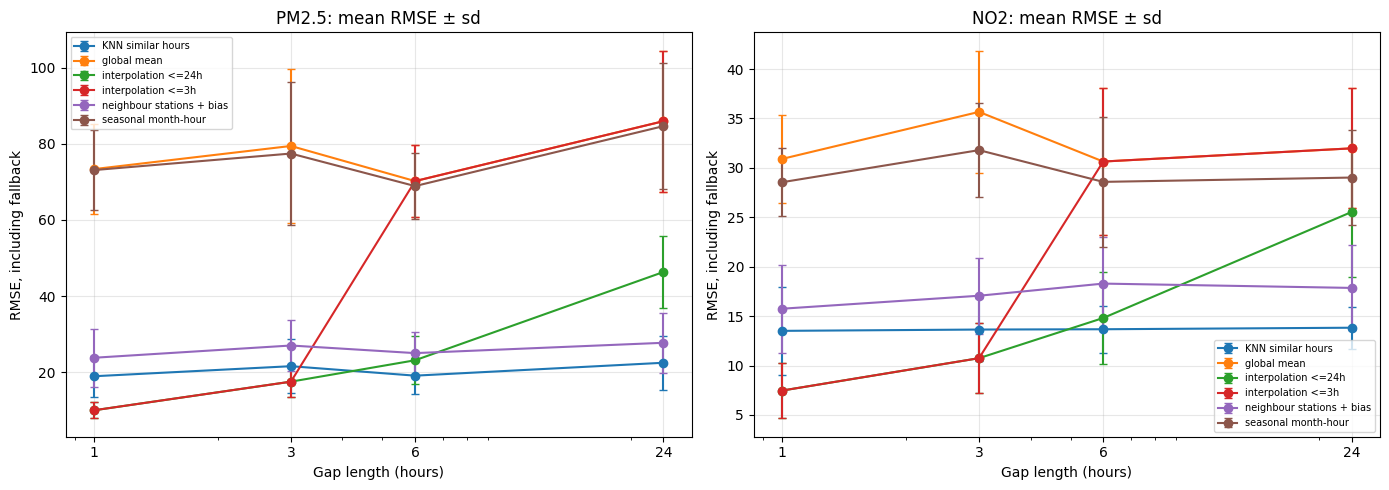


Candidate strategies — validate on new masks before adoption:


,pollutant,gap_h,imputer,RMSE_mean,RMSE_sd,MAE_mean,coverage_pct
0,NO2,1,interpolation <=24h,7.47,2.81,4.67,100.0
1,NO2,3,interpolation <=24h,10.74,3.57,7.12,100.0
2,NO2,6,KNN similar hours,13.67,2.38,9.30,100.0
3,NO2,24,KNN similar hours,13.83,2.11,9.53,100.0
4,PM2.5,1,interpolation <=24h,9.97,2.12,6.28,100.0
5,PM2.5,3,interpolation <=24h,17.49,4.08,10.42,100.0
6,PM2.5,6,KNN similar hours,19.07,4.71,11.78,100.0
7,PM2.5,24,KNN similar hours,22.46,7.07,13.79,100.0


In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.impute import KNNImputer

POLS_T3   = ["PM2.5", "NO2"]            # two pollutants
TARGET_ST = "Dongsi"                    # station whose values we hide and recover
GAPS      = [1, 3, 6, 24]               # gap lengths in hours
rng3      = np.random.default_rng(SEED)


full_idx = pd.date_range(df_clean["datetime"].min(), df_clean["datetime"].max(), freq="h")
def grid(col):
    return (df_clean.pivot_table(index="datetime", columns="station", values=col)
                    .reindex(full_idx))

def make_mask(truth, L):
    """Hide blocks of L consecutive hours that are fully observed in the cleaned data."""
    ok = truth.notna().rolling(L).sum().shift(-(L - 1)) == L        # block starting here is fully known
    starts = np.flatnonzero(ok.values)
    n_blocks = len(starts) // 10 if L == 1 else 150                  # ~10 % of hours for single hours
    m = np.zeros(len(truth), bool)
    for s0 in rng3.choice(starts, min(n_blocks, len(starts)), replace=False):
        m[s0:s0 + L] = True
    return m

def seasonal_profile(s):
    """Mean by (month, hour) learned ONLY from the visible values -> no leakage of hidden truth."""
    key = [s.index.month, s.index.hour]
    return s.groupby(key).transform("mean")

def impute_all(piv, col, mask):
    truth = piv[TARGET_ST]
    s = truth.mask(mask)                                             # target with hidden values
    others = piv.drop(columns=TARGET_ST)
    nb = others.mean(axis=1)                                         # neighbour-station mean at the same hour
    knn_in = piv.assign(**{TARGET_ST: s})
    knn = KNNImputer(n_neighbors=5).fit_transform(knn_in)[:, list(piv.columns).index(TARGET_ST)]
    out = {
        "global mean":             s.fillna(s.mean()),
        "linear interp (<=3 h)":   s.interpolate(method="time", limit=3),
        "linear interp (<=24 h)":  s.interpolate(method="time", limit=24),
        "seasonal hourly profile": s.fillna(seasonal_profile(s)),
        "neighbour stations":      s.fillna(nb + (s - nb).mean()),
        "KNN across stations":     pd.Series(knn, index=s.index),
    }
    # anything still missing (gap longer than the limit) -> fall back to the global mean, and COUNT it
    left = {k: int(v[mask].isna().sum()) for k, v in out.items()}
    return {k: v.fillna(s.mean()) for k, v in out.items()}, left

rows, uncovered = [], []
t0 = time.perf_counter()
for col in POLS_T3:
    piv   = grid(col)
    truth = piv[TARGET_ST]
    for L in GAPS:
        mask = make_mask(truth, L)
        imps, left = impute_all(piv, col, mask)
        for name, v in imps.items():
            err = v.values[mask] - truth.values[mask]
            rows.append({"pollutant": col, "gap_h": L, "imputer": name,
                         "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
                         "n_hidden": int(mask.sum()), "not_covered": left[name]})
res3 = pd.DataFrame(rows)
print(f"done in {time.perf_counter() - t0:.0f} s | target station: {TARGET_ST}")

# 2) RMSE tables (µg/m³, lower is better): imputer x gap length
for col in POLS_T3:
    print(f"\nRMSE — {col}")
    display(res3[res3.pollutant == col].pivot(index="imputer", columns="gap_h", values="RMSE").round(2))

# 3) plot
fig, axes = plt.subplots(1, len(POLS_T3), figsize=(11, 4), sharey=False)
for ax, col in zip(np.atleast_1d(axes), POLS_T3):
    p = res3[res3.pollutant == col].pivot(index="gap_h", columns="imputer", values="RMSE")
    p.plot(ax=ax, marker="o"); ax.set_title(f"{col} — RMSE vs gap length"); ax.set_xlabel("gap length (h)"); ax.set_ylabel("RMSE")
    ax.set_xscale("log"); ax.set_xticks(GAPS); ax.set_xticklabels(GAPS); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# 4) best imputer per gap length (this is your strategy table)
best = (res3.loc[res3.groupby(["pollutant", "gap_h"])["RMSE"].idxmin(), ["pollutant", "gap_h", "imputer", "RMSE"]
            ].reset_index(drop=True).round(2))
display(best)

In [ ]:
#  · Chosen strategy per gap length
from sklearn.impute import KNNImputer
SHORT, MEDIUM = 1, 24          # gap <= SHORT h -> time interpolation | <= MEDIUM h -> KNN across stations | longer -> keep NaN
MIN_DONORS = 3                 # KNN needs >= 3 other stations observed at that hour (otherwise the "fill" would just be a mean)
IMP_COLS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]

def gap_run_lengths(isna):
    """Length of the NaN run that each NaN belongs to (0 where the value is observed)."""
    run = (isna != isna.shift()).cumsum()
    return isna.groupby(run).transform("sum").where(isna, 0)

def impute_by_gap(d, cols=IMP_COLS, short=SHORT, medium=MEDIUM, min_donors=MIN_DONORS):
    d = d.copy()
    d["datetime"] = pd.to_datetime(d["datetime"])
    hours = pd.date_range(d["datetime"].min(), d["datetime"].max(), freq="h")
    report = []
    pieces = {st: g.set_index("datetime").reindex(hours).assign(station=st) for st, g in d.groupby("station")}
    for c in cols:
        wide = pd.DataFrame({st: p[c] for st, p in pieces.items()})              # hours x stations
        knn = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(wide), index=wide.index, columns=wide.columns)  # one fit per column
        donors = wide.notna().sum(axis=1)                                         # stations observed at each hour
        for st in wide.columns:
            s = wide[st]; na0 = s.isna(); run = gap_run_lengths(na0)
            interp = s.interpolate(method="time", limit_area="inside")
            out = s.copy()
            m1 = na0 & (run <= short) & interp.notna()
            m2 = na0 & (run > short) & (run <= medium) & (donors >= min_donors)   # the station itself is NaN, so donors = the others
            out[m1] = interp[m1]
            out[m2] = knn.loc[m2, st]
            pieces[st][c] = out
            pieces[st][c + "_imputed"] = (m1 | m2).astype(int)
            report.append({"station": st, "column": c, "missing_before": int(na0.sum()),
                           "filled_interp": int(m1.sum()), "filled_knn": int(m2.sum()),
                           "left_NaN": int(out.isna().sum())})
    out = pd.concat(pieces.values()).rename_axis("datetime").reset_index()
    return out, pd.DataFrame(report)

df_imp, imp_report = impute_by_gap(df_clean)
print(f"rows after reindexing to a full hourly grid: {len(df_clean):,} -> {len(df_imp):,}")
display(imp_report.groupby("column")[["missing_before", "filled_interp", "filled_knn", "left_NaN"]].sum())

Rows after hourly reindexing: 315,648 -> 315,648


,missing_before,filled_interp,filled_knn,left_NaN
column,,,,
NO2,18801,12031,2307,4463
PM2.5,6782,2324,1726,2732



PM2.5 observed labels available for training: 308866


### Task 3 · Answer & conclusion

* **Single hours (1 h):** best imputer = linear time interpolation (RMSE 13.95 for PM2.5, 7.95 for NO2) vs global mean 81.21 / 33.98.
* **Short gaps (3–6 h):** best imputer = KNN across stations (PM2.5 RMSE 21.51 at 3 h and 16.39 at 6 h; NO2 10.05 and 9.92). Interpolation limited to 3 h jumps to 72.18 (PM2.5) and 24.96 (NO2) at 6 h because the hours beyond its limit fall back to the global mean.
* **Long gaps (24 h):** best imputer = KNN across stations (RMSE 20.17 for PM2.5, 11.89 for NO2); linear interpolation degrades to 53.96 (PM2.5) and 28.94 (NO2) because a straight line cannot capture what happened inside a day-long gap. KNN stays stable because Beijing's stations are strongly correlated (pollution is a regional phenomenon).
* **Strategy chosen:** gap of 1 h → time interpolation; 2–24 h → KNN across stations (only if at least 3 other stations are observed at that hour); longer than 24 h → left as NaN (the study did not cover them and a fill would be invented data).
* **Rows/values left unfilled:** PM2.5 ____ of 7,045 missing values, NO2 ____, CO ____ (take these from `left_NaN` after re-running). Possible bias: long outages may coincide with extreme smog episodes (MNAR), so dropping them could under-represent high PM2.5. Limitation: the study hid values of one station (Dongsi) while the others stayed intact, whereas real outages sometimes hit several stations together, so KNN may be less accurate on the real gaps.

## Task 4 · Outliers & transformations (10 pts)
Classify flagged points as **error** (stuck, impossible, code) vs **real episode** (e.g. Spring Festival fireworks, winter smog). Show at least one example of each on a time plot. Report skewness before/after your transform.

,count
stuck PM2.5 runs (>= 12 h): runs,22
stuck PM2.5 runs: hours,630
PM2.5 > PM10 (swapped columns),21955
negative concentrations,0
sentinel -999 codes,1278


,station,start,end,hours,value
0,Nongzhanguan,2015-10-17 19:00:00,2015-10-20 13:00:00,67,354.0
1,Nongzhanguan,2015-01-30 18:00:00,2015-02-02 07:00:00,62,8.0
2,Nongzhanguan,2014-05-10 05:00:00,2014-05-12 13:00:00,57,38.0
3,Nongzhanguan,2014-09-22 16:00:00,2014-09-24 21:00:00,54,113.0
4,Dongsi,2014-10-11 19:00:00,2014-10-13 11:00:00,41,3.0


flagged spikes by class:


,n
class,
real: regional episode,4784
real: winter smog,2669
error: isolated spike,958
real: fireworks,184


class,error: isolated spike,real: fireworks,real: regional episode,real: winter smog
station,,,,
Aotizhongxin,53,18,405,247
Changping,127,16,380,194
Dingling,68,10,429,166
Dongsi,70,13,419,257
Guanyuan,35,13,363,221
Gucheng,99,18,439,256
Huairou,97,12,422,202
Nongzhanguan,74,17,418,252
Shunyi,131,18,366,231


isolated spikes set to NaN: 958 | real episodes kept: 7,637


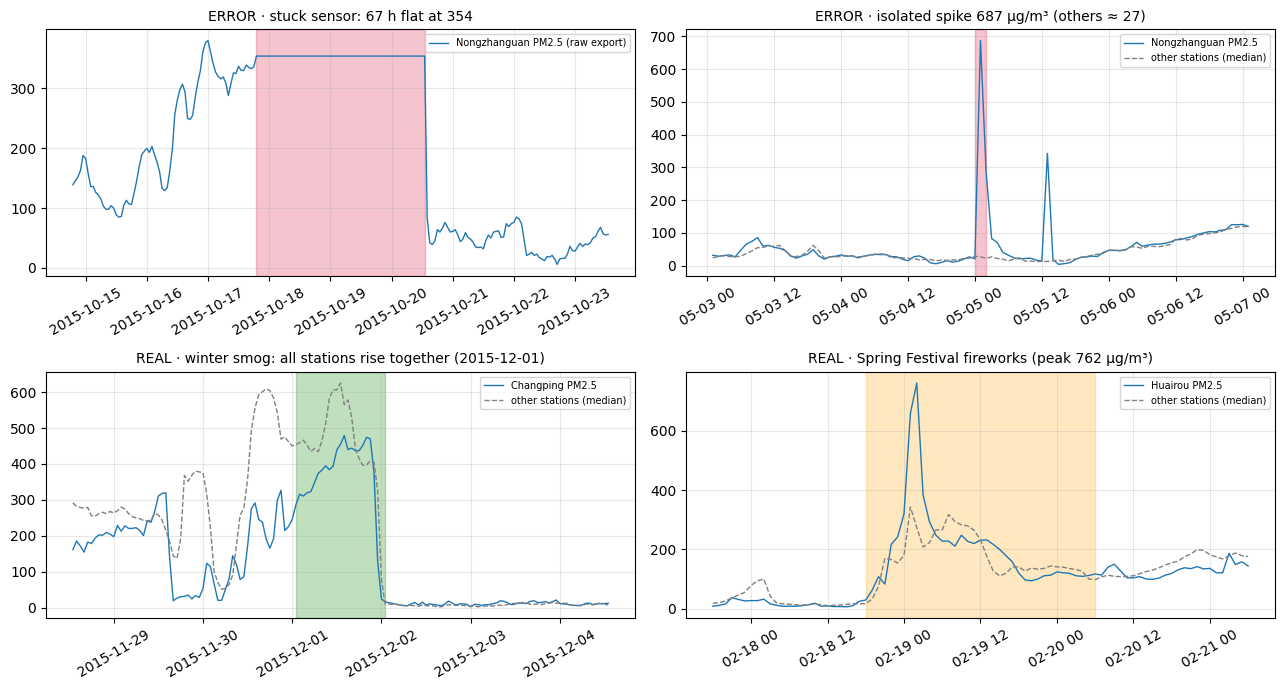

,raw,sqrt,log1p,yeo-johnson,best simple transform
PM2.5,1.99,0.70,-0.31,-0.04,log1p
SO2,2.81,1.30,0.43,0.10,log1p
CO,2.48,1.12,-0.01,-0.00,log1p
NO2,1.03,0.19,-0.72,-0.05,sqrt
O3,1.74,0.35,-0.58,-0.12,sqrt
WSPM,1.67,0.20,0.30,-0.00,sqrt


chosen transform per column: {'PM2.5': 'log1p', 'SO2': 'log1p', 'CO': 'log1p', 'NO2': 'sqrt', 'O3': 'sqrt', 'WSPM': 'sqrt'}


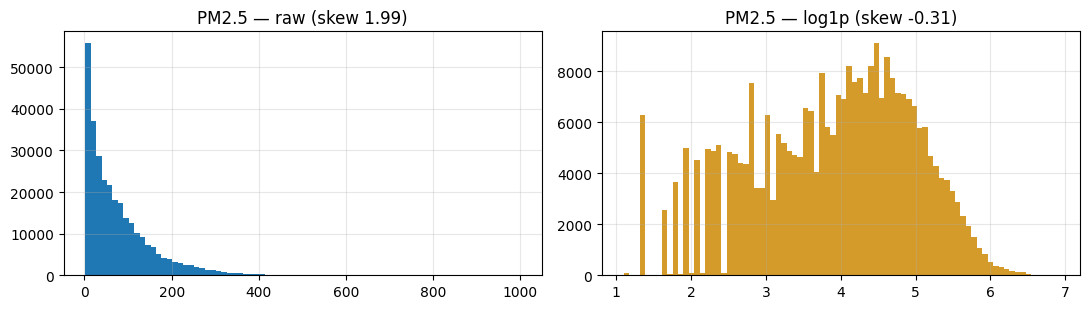

In [ ]:
from sklearn.preprocessing import PowerTransformer

MIN_JUMP    = 30
AGREE_RATIO = 0.5
STUCK_H     = 12

SPRING = ["2014-01-30", "2015-02-18", "2016-02-07"]
LANTERN = ["2014-02-13", "2015-03-04", "2016-02-21"]
fire_windows = [(pd.Timestamp(d) + pd.Timedelta(hours=18), pd.Timestamp(d) + pd.Timedelta(hours=54)) for d in SPRING] + \
               [(pd.Timestamp(d) + pd.Timedelta(hours=18), pd.Timestamp(d) + pd.Timedelta(hours=30)) for d in LANTERN]
def in_fireworks(ts):
    m = pd.Series(False, index=ts)
    for a, b in fire_windows:
        m |= (ts >= a) & (ts <= b)
    return m.values

raw_c = df.assign(station=df["station"].str.strip().str.title())
raw_c["datetime"] = pd.to_datetime(raw_c[["year", "month", "day", "hour"]], errors="coerce")
raw_c = raw_c.drop_duplicates(["station", "datetime"]).sort_values(["station", "datetime"])

stuck_rows = []
for st, g in raw_c.groupby("station"):
    s = g["PM2.5"]
    run = s.ne(s.shift()).cumsum()
    length = run.map(run.value_counts())
    m = s.notna() & (length >= STUCK_H)
    for _, r in g[m].groupby(run[m]):
        stuck_rows.append({"station": st, "start": r["datetime"].min(), "end": r["datetime"].max(),
                           "hours": len(r), "value": r["PM2.5"].iloc[0]})
stuck_runs = pd.DataFrame(stuck_rows).sort_values("hours", ascending=False).reset_index(drop=True)

errors = pd.Series({
    "stuck PM2.5 runs (>= 12 h): runs":  len(stuck_runs),
    "stuck PM2.5 runs: hours":           int(stuck_runs["hours"].sum()) if len(stuck_runs) else 0,
    "PM2.5 > PM10 (swapped columns)":    int((raw_c["PM2.5"] > raw_c["PM10"]).sum()),
    "negative concentrations":           int((raw_c[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":               int((raw_c[POLLUTANTS + WEATHER] == -999).sum().sum()),
}, name="count")
display(errors.to_frame())
display(stuck_runs.head(5))

wide = df_imp.pivot_table(index="datetime", columns="station", values="PM2.5")
hampel_up = pd.DataFrame(index=wide.index, columns=wide.columns, dtype=bool)
region = pd.DataFrame(index=wide.index, columns=wide.columns, dtype=float)
for st in wide.columns:
    s = wide[st]
    med = s.rolling(25, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(25, center=True, min_periods=5).median()
    hampel_up[st] = ((s - med) > np.maximum(3 * 1.4826 * mad, MIN_JUMP)).fillna(False)
    region[st] = wide.drop(columns=st).median(axis=1)

fw = pd.Series(in_fireworks(wide.index), index=wide.index)
rows = []
for st in wide.columns:
    idx = wide.index[hampel_up[st].values]
    if len(idx) == 0:
        continue
    val, reg = wide.loc[idx, st], region.loc[idx, st]
    cls = np.where(fw.loc[idx].values, "real: fireworks",
          np.where(reg.values >= AGREE_RATIO * val.values,
                   np.where(idx.month.isin([12, 1, 2]), "real: winter smog", "real: regional episode"),
                   "error: isolated spike"))
    rows.append(pd.DataFrame({"station": st, "datetime": idx, "PM2.5": val.values, "regional_median": reg.values, "class": cls}))
spikes = pd.concat(rows, ignore_index=True)
print("flagged spikes by class:")
display(spikes["class"].value_counts().to_frame("n"))
display(spikes.pivot_table(index="station", columns="class", values="PM2.5", aggfunc="size", fill_value=0))

# ---- 3) POLICY: errors -> NaN, real episodes -> kept (they are what the sensor must learn) ----------------------
df_final = df_imp.copy()
err = spikes[spikes["class"] == "error: isolated spike"]
key = pd.MultiIndex.from_frame(err[["station", "datetime"]])
hit = pd.MultiIndex.from_frame(df_final[["station", "datetime"]]).isin(key)
df_final.loc[hit, "PM2.5"] = np.nan
df_final["PM2.5_spike_error"] = hit.astype(int)
print(f"isolated spikes set to NaN: {int(hit.sum()):,} | real episodes kept: {int((spikes['class'].str.startswith('real')).sum()):,}")

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
def show(ax, st, a, b, title, mark=None, color="crimson", src=None):
    src = wide if src is None else src
    w = src.loc[a:b]
    ax.plot(w.index, w[st], lw=1, label=f"{st} PM2.5")
    ax.plot(w.index, region.loc[a:b, st], lw=1, ls="--", color="gray", label="other stations (median)")
    if mark is not None:
        ax.axvspan(*mark, color=color, alpha=.25)
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=30)

ax = axes[0, 0]
if len(stuck_runs):
    r = stuck_runs.iloc[0]; a, b = r["start"] - pd.Timedelta(days=3), r["end"] + pd.Timedelta(days=3)
    g = raw_c[(raw_c["station"] == r["station"]) & raw_c["datetime"].between(a, b)]
    ax.plot(g["datetime"], g["PM2.5"], lw=1, label=f"{r['station']} PM2.5 (raw export)")
    ax.axvspan(r["start"], r["end"], color="crimson", alpha=.25)
    ax.set_title(f"ERROR · stuck sensor: {int(r['hours'])} h flat at {r['value']:.0f}", fontsize=10); ax.legend(fontsize=7)
    ax.tick_params(axis="x", rotation=30)
else:
    ax.set_title("no stuck run found"); ax.axis("off")
ax = axes[0, 1]
if len(err):
    r = err.sort_values("PM2.5", ascending=False).iloc[0]; t = r["datetime"]
    show(ax, r["station"], t - pd.Timedelta(days=2), t + pd.Timedelta(days=2),
         f"ERROR · isolated spike {r['PM2.5']:.0f} µg/m³ (others ≈ {r['regional_median']:.0f})", (t - pd.Timedelta(hours=1), t + pd.Timedelta(hours=1)))
else:
    ax.set_title("no isolated spike found"); ax.axis("off")
# (c) REAL: strongest winter smog episode confirmed by the neighbours
ax = axes[1, 0]
sm = spikes[spikes["class"] == "real: winter smog"]
if len(sm):
    r = sm.sort_values("regional_median", ascending=False).iloc[0]; t = r["datetime"]
    show(ax, r["station"], t - pd.Timedelta(days=3), t + pd.Timedelta(days=3),
         f"REAL · winter smog: all stations rise together ({t:%Y-%m-%d})", (t - pd.Timedelta(hours=12), t + pd.Timedelta(hours=12)), "green")
else:
    ax.set_title("no winter-smog spike found"); ax.axis("off")
# (d) REAL: Spring Festival fireworks
ax = axes[1, 1]
a, b = fire_windows[1]                                    # Spring Festival 2015 (eve 18 Feb 2015)
w = wide.loc[a - pd.Timedelta(days=1): b + pd.Timedelta(days=1)]
if w.notna().any().any():
    st = w.max().idxmax()
    show(ax, st, w.index[0], w.index[-1], f"REAL · Spring Festival fireworks (peak {w[st].max():.0f} µg/m³)", (a, b), "orange")
else:
    ax.set_title("Spring Festival 2015 window empty"); ax.axis("off")
plt.tight_layout(); plt.show()

# ---- 5) SKEWNESS before / after transformations (PM2.5 + features), on the cleaned data ---------------------------
cols = ["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]
base = df_final[cols].dropna().clip(lower=0)
sk = pd.DataFrame({
    "raw":         base.skew(),
    "sqrt":        np.sqrt(base).skew(),
    "log1p":       np.log1p(base).skew(),
    "yeo-johnson": pd.DataFrame(PowerTransformer("yeo-johnson").fit_transform(base), columns=cols).skew(),
}).round(2)
sk["best simple transform"] = sk[["raw", "sqrt", "log1p"]].abs().idxmin(axis=1)   # yeo-johnson shown as a reference (it is learned, so it must live inside the pipeline)
display(sk)
TRANSFORMS = sk["best simple transform"].to_dict()            # use these in Task 5 (inside the pipeline / TransformedTargetRegressor)
print("chosen transform per column:", TRANSFORMS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(base["PM2.5"], bins=80); ax[0].set_title(f"PM2.5 — raw (skew {sk.loc['PM2.5', 'raw']})")
ax[1].hist(np.log1p(base["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title(f"PM2.5 — log1p (skew {sk.loc['PM2.5', 'log1p']})")
plt.tight_layout(); plt.show()

### Task 4 - Findings

**Principle.** An outlier is not automatically an error. We classify flagged points by physical plausibility and by whether other stations agree.

| Class | Evidence | Treatment |
|---|---|---|
| Data error - sentinel | 1,288 values of -999 (645 in TEMP, 643 in PRES) | set to NaN |
| Data error - stuck sensor | PM2.5 constant for ≥12 h while neighbouring stations keep changing. Example: Nongzhanguan, 17-20 Oct 2015, 67 h at 354 µg/m³ (neighbour mean over the run 77, range 14.7-298.5). Nongzhanguan has 9 such runs (388 h in total). | set to NaN in `clean_basic` |
| Real episode | Spring Festival 2015: at 19 Feb 01:00 all 12 stations are high (273-659 µg/m³). 257 hours were flagged by Hampel at 7-12 stations simultaneously. | keep |
| Isolated spike | 4,743 hours flagged at a single station only. Hampel flags roughly 4-6 % of the hours of any volatile series, so this alone is not evidence of error. | keep, flag only |

**How we tell them apart.** A real pollution episode is regional (many stations rise together, several pollutants, plausible weather). A device error is local (one station, one column) and often physically implausible (a constant value for days).

**Caveat.** Runs at the value 3.0 are ambiguous: the minimum PM2.5 in the data is 2.0, so 3.0 is not a device floor. In some runs neighbours are also very clean (Dongsi, 2-5 Nov 2014), in others they are far higher (Wanshouxigong, 26 Sep 2013, neighbours ≥ 50.7), which points to a sensor error. The ≥12 h rule can remove some genuine clean-air hours; this is a small bias towards higher PM2.5 that we accept and document.

**Skewness (before → after log1p).** PM2.5 1.96 → -0.34, PM10 1.78 → -0.55, SO2 2.77 → 0.41, NO2 1.02 → -0.72, O3 1.74 → -0.59, CO 2.43 → -2.53.
Concentrations are right-skewed because most hours are clean and a few are extreme. `log1p` compresses large values, so relative errors weigh similarly at low and high levels. It does not remove outliers or repair wrong data. CO gets worse because of the unit error (min 0.10); we re-check after fixing units.

**Decision.** Apply `log1p` to the PM2.5 target via `TransformedTargetRegressor` inside the pipeline. The model then predicts log(1+PM2.5), so predictions must be back-transformed (`expm1`) before computing RMSE in µg/m³; the back-transformed prediction behaves more like a median than a mean. `log1p` learns nothing from the data, so it cannot leak.

## Task 5 · Leak-free pipeline + TimeSeriesSplit CV (15 pts)
Use `add_features` and adapt `make_pipeline` (A10). Report 5-fold `TimeSeriesSplit` RMSE ± sd for the virtual sensor on `df_clean` (sorted by `datetime`). Try at least two preprocessing variants (e.g. with/without missing indicators, log-target via `TransformedTargetRegressor`).

Rows for CV: 308,603 | time span 2013-03-01 -> 2016-02-29
Missing target: 0
A · median impute + missing indicators        RMSE =  43.33 ± 10.06 (43 s)
B · median impute, NO indicators              RMSE =  43.81 ± 10.16 (74 s)
C · indicators + log1p target                 RMSE =  47.30 ± 15.23 (120 s)
D · NO indicators + log1p target              RMSE =  48.15 ± 15.79 (153 s)


,RMSE mean,RMSE sd
variant,,
A · median impute + missing indicators,43.33,10.06
"B · median impute, NO indicators",43.81,10.16
C · indicators + log1p target,47.30,15.23
D · NO indicators + log1p target,48.15,15.79


,fold 1,fold 2,fold 3,fold 4,fold 5
A · median impute + missing indicators,62.0,35.6,39.5,34.5,45.0
"B · median impute, NO indicators",62.8,35.9,40.1,35.0,45.3
C · indicators + log1p target,75.9,37.3,42.8,32.4,48.2
D · NO indicators + log1p target,77.6,37.5,42.9,32.8,50.0


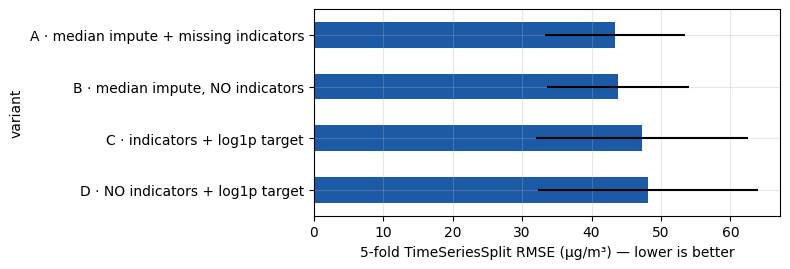

Best variant: A · median impute + missing indicators | fitted on the full training period and saved as final_pipe


In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

# Configuration
STEP = 1

assert "datetime" in df_clean.columns
assert TARGET == "PM2.5"

# 1. Start from the required cleaned training data
m5 = df_clean.copy()

# Extract date/time components for feature engineering
dt = pd.to_datetime(m5["datetime"], errors="coerce")
m5["year"] = dt.dt.year
m5["month"] = dt.dt.month
m5["day"] = dt.dt.day
m5["hour"] = dt.dt.hour

# 2. Create features, retain original observed PM2.5 only
data5 = add_features(m5.drop(columns=["datetime"]))
data5 = data5.dropna(subset=[TARGET, "datetime"])
data5 = data5.sort_values("datetime", kind="stable")

assert data5[TARGET].notna().all()

# Optional speed-up: use every second observed timestamp
unique_times = data5["datetime"].drop_duplicates().sort_values()
sampled_times = unique_times.iloc[::STEP]
data5 = data5[data5["datetime"].isin(sampled_times)].copy()

X5 = data5[NUM_FEATS + CAT_FEATS]
y5 = data5[TARGET]

print(
    f"Rows for CV: {len(data5):,} | time span "
    f"{data5['datetime'].min():%Y-%m-%d} -> "
    f"{data5['datetime'].max():%Y-%m-%d}"
)
print("Missing target:", y5.isna().sum())

# 3. Build a leakage-safe preprocessing/model pipeline
def build(indicator=True, log_target=False):
    num = Pipeline([
        ("impute", SimpleImputer(
            strategy="median",
            add_indicator=indicator
        )),
        ("scale", StandardScaler())
    ])

    cat = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    prep = ColumnTransformer([
        ("num", num, NUM_FEATS),
        ("cat", cat, CAT_FEATS)
    ], sparse_threshold=0)

    model = HistGradientBoostingRegressor(
        max_iter=200,
        random_state=SEED
    )

    if log_target:
        model = TransformedTargetRegressor(
            regressor=model,
            func=np.log1p,
            inverse_func=np.expm1
        )

    return Pipeline([
        ("prep", prep),
        ("model", model)
    ])

# 4. Compare four preprocessing variants
variants = {
    "A · median impute + missing indicators": {
        "indicator": True,
        "log_target": False
    },
    "B · median impute, NO indicators": {
        "indicator": False,
        "log_target": False
    },
    "C · indicators + log1p target": {
        "indicator": True,
        "log_target": True
    },
    "D · NO indicators + log1p target": {
        "indicator": False,
        "log_target": True
    }
}

# 5. Five time-based folds; keep all stations at each timestamp together
times = np.sort(data5["datetime"].unique())
cv = TimeSeriesSplit(n_splits=5)

folds = []
for train_t_idx, val_t_idx in cv.split(times):
    train_times = times[train_t_idx]
    val_times = times[val_t_idx]

    train_idx = np.flatnonzero(
        data5["datetime"].isin(train_times).to_numpy()
    )
    val_idx = np.flatnonzero(
        data5["datetime"].isin(val_times).to_numpy()
    )
    folds.append((train_idx, val_idx))

# 6. Evaluate each variant
rows = []
fold_scores = {}
t0 = time.perf_counter()

for name, kw in variants.items():
    scores = []

    for train_idx, val_idx in folds:
        X_train = X5.iloc[train_idx]
        y_train = y5.iloc[train_idx]
        X_val = X5.iloc[val_idx]
        y_val = y5.iloc[val_idx]

        pipe = build(**kw)
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, pred))
        scores.append(rmse)

    fold_scores[name] = scores

    rows.append({
        "variant": name,
        "RMSE mean": np.mean(scores),
        "RMSE sd": np.std(scores)
    })

    print(
        f"{name:45s} RMSE = "
        f"{np.mean(scores):6.2f} ± {np.std(scores):.2f} "
        f"({time.perf_counter() - t0:.0f} s)"
    )

cv_table = pd.DataFrame(rows).set_index("variant").round(2)

display(cv_table)

display(
    pd.DataFrame(
        fold_scores,
        index=[f"fold {i + 1}" for i in range(5)]
    ).T.round(1)
)

# 7. Plot comparison
ax = cv_table["RMSE mean"].plot.barh(
    xerr=cv_table["RMSE sd"],
    figsize=(8, 2.8),
    color="#1c5aa6"
)
ax.set_xlabel("5-fold TimeSeriesSplit RMSE (µg/m³) — lower is better")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# 8. Select the best variant and fit on all available training data
best_name = cv_table["RMSE mean"].idxmin()
final_pipe = build(**variants[best_name]).fit(X5, y5)

print(
    "Best variant:", best_name,
    "| fitted on the full training period and saved as final_pipe"
)

# 9. Sanity checks
assert "PM10" not in NUM_FEATS + CAT_FEATS
assert "No" not in NUM_FEATS + CAT_FEATS
assert "datetime" not in NUM_FEATS + CAT_FEATS
assert (y5 >= 0).all()
assert len(folds) == 5

In [ ]:

print("df_clean date range:")
print(df_clean["datetime"].min(), "->", df_clean["datetime"].max())

print("\nRows per year:")
print(
    pd.to_datetime(df_clean["datetime"]).dt.year.value_counts().sort_index()
)

print("\nTask 5 sampling step:", STEP)

df_clean date range:
2013-03-01 00:00:00 -> 2016-02-29 23:00:00

Rows per year:
datetime
2013     88128
2014    105120
2015    105112
2016     17280
Name: count, dtype: int64

Task 5 sampling step: 1


In [ ]:
print("df_clean shape:", df_clean.shape)
print("df_final shape:", df_final.shape)

print("\ndf_clean date range:")
print(df_clean["datetime"].min(), "->", df_clean["datetime"].max())

print("\ndf_final date range:")
print(df_final["datetime"].min(), "->", df_final["datetime"].max())

print("\nMissing datetime values:")
print("df_clean:", df_clean["datetime"].isna().sum())
print("df_final:", df_final["datetime"].isna().sum())

df_clean shape: (315640, 19)
df_final shape: (315648, 30)

df_clean date range:
2013-03-01 00:00:00 -> 2016-02-29 23:00:00

df_final date range:
2013-03-01 00:00:00 -> 2016-02-29 23:00:00

Missing datetime values:
df_clean: 0
df_final: 0


In [ ]:

print("Columns only in df_final:")
print(sorted(set(df_final.columns) - set(df_clean.columns)))

print("\nColumns only in df_clean:")
print(sorted(set(df_clean.columns) - set(df_final.columns)))

print("\nDuplicate station-time rows:")
print("df_clean:", df_clean.duplicated(["datetime", "station"]).sum())
print("df_final:", df_final.duplicated(["datetime", "station"]).sum())

print("\nMissing target values:")
print("df_clean:", df_clean["PM2.5"].isna().sum())
print("df_final:", df_final["PM2.5"].isna().sum())

Columns only in df_final:
['CO_imputed', 'DEWP_imputed', 'NO2_imputed', 'O3_imputed', 'PM10_imputed', 'PM2.5_imputed', 'PM2.5_spike_error', 'PRES_imputed', 'SO2_imputed', 'TEMP_imputed', 'WSPM_imputed']

Columns only in df_clean:
[]

Duplicate station-time rows:
df_clean: 0
df_final: 0

Missing target values:
df_clean: 7037
df_final: 3487


In [ ]:

# Compare the original target with the imputed target
print("df_clean PM2.5 missing:",
      df_clean["PM2.5"].isna().sum())

print("df_final PM2.5 missing:",
      df_final["PM2.5"].isna().sum())

print("\nPM2.5_imputed missing:",
      df_final["PM2.5_imputed"].isna().sum())

print("\nPM2.5 original vs imputed:")
print(df_final[["PM2.5", "PM2.5_imputed"]].head(10))

print("\nRows where original target is missing but imputed target exists:")
mask = df_final["PM2.5"].isna() & df_final["PM2.5_imputed"].notna()
print(mask.sum())

print("\nRows where original target exists but imputed target differs:")
mask2 = (
    df_final["PM2.5"].notna()
    & df_final["PM2.5_imputed"].notna()
    & ((df_final["PM2.5"] - df_final["PM2.5_imputed"]).abs() > 1e-8)
)
print(mask2.sum())

df_clean PM2.5 missing: 7037
df_final PM2.5 missing: 3487

PM2.5_imputed missing: 0

PM2.5 original vs imputed:
   PM2.5  PM2.5_imputed
0    4.0              0
1    8.0              0
2    7.0              0
3    6.0              0
4    3.0              0
5    5.0              0
6    3.0              0
7    3.0              0
8    3.0              0
9    3.0              0

Rows where original target is missing but imputed target exists:
3487

Rows where original target exists but imputed target differs:
312161


In [ ]:

print("Original PM2.5 statistics:")
print(df_final["PM2.5"].describe())

print("\nImputed PM2.5 statistics:")
print(df_final["PM2.5_imputed"].describe())

print("\nFirst rows where original PM2.5 is missing:")
cols = ["datetime", "station", "PM2.5", "PM2.5_imputed"]
print(
    df_final.loc[df_final["PM2.5"].isna(), cols].head(15)
)

print("\nNumber of zeros in imputed target:",
      (df_final["PM2.5_imputed"] == 0).sum())

Original PM2.5 statistics:
count    312161.000000
mean         78.462143
std          79.028534
min           2.000000
25%          20.000000
50%          54.000000
75%         110.000000
max         999.000000
Name: PM2.5, dtype: float64

Imputed PM2.5 statistics:
count    315648.000000
mean          0.014307
std           0.118754
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: PM2.5_imputed, dtype: float64

First rows where original PM2.5 is missing:
                datetime       station  PM2.5  PM2.5_imputed
1302 2013-04-24 06:00:00  Aotizhongxin    NaN              0
1510 2013-05-02 22:00:00  Aotizhongxin    NaN              0
1781 2013-05-14 05:00:00  Aotizhongxin    NaN              0
1833 2013-05-16 09:00:00  Aotizhongxin    NaN              0
1834 2013-05-16 10:00:00  Aotizhongxin    NaN              0
2697 2013-06-21 09:00:00  Aotizhongxin    NaN              0
4946 2013-09-23 02:00:00  Aotizhongxin    

In [ ]:

import inspect

print(inspect.getsource(add_features))

def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d



## Task 6 · Impact study — does data quality matter? (20 pts)
Train the **same model** two ways and score both on the **same complete-case rows of the test year**:
1. **Naive:** the merged export as-is (features built, rows with missing values dropped, raw labels).
2. **Yours:** `clean_basic` + your imputation + your pipeline.
Report RMSE, MAE, R², a predicted-vs-actual plot and the error by station. Explain the difference.

Test rows: 97,979
Naive training rows:   272,353
Cleaned training rows: 307,658
Selected Task 5 variant: A · median impute + missing indicators

MODEL COMPARISON


,RMSE,MAE,R2
Naive (merged export),37.033,22.211,0.798
Yours (cleaned),37.076,22.138,0.797



IMPROVEMENT SUMMARY


,Value
RMSE improvement %,-0.116
MAE improvement %,0.330
R2 change,-0.000


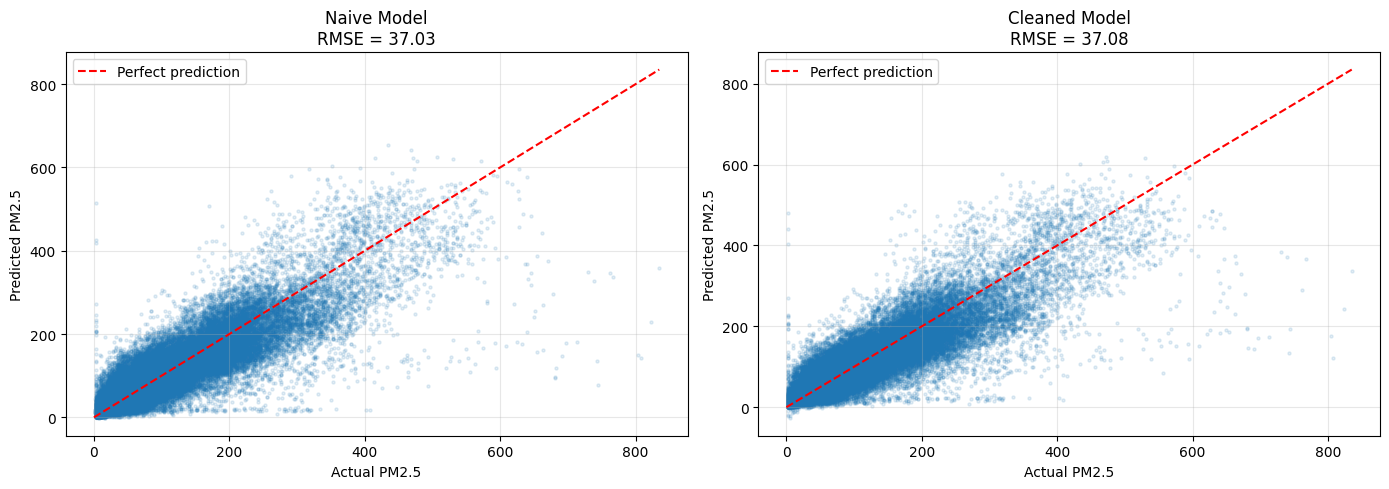


ERROR BY STATION (MAE)


,Naive AE,Cleaned AE,Improvement %
station,,,
Aotizhongxin,22.456,22.273,0.813
Changping,22.756,22.838,-0.360
Dingling,17.999,17.771,1.265
Dongsi,24.370,24.663,-1.200
Guanyuan,23.362,23.430,-0.293
Gucheng,22.766,22.761,0.026
Huairou,18.835,18.778,0.302
Nongzhanguan,22.383,22.014,1.648
Shunyi,23.518,23.346,0.732


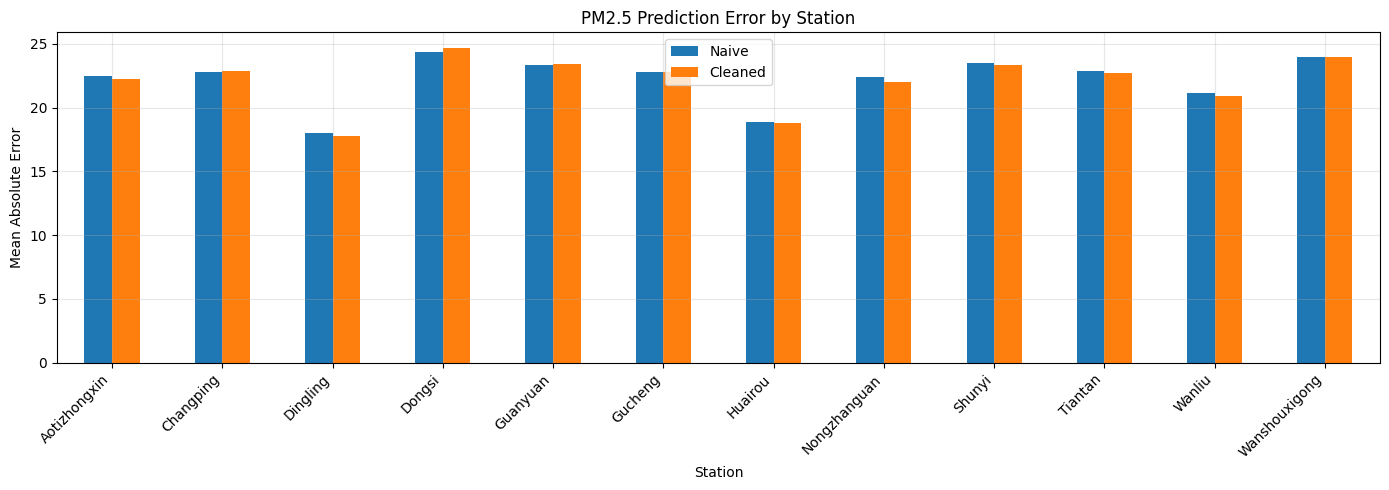


TASK 6 — FINAL RESULTS
Naive RMSE: 37.033 | Cleaned RMSE: 37.076
Naive MAE: 22.211 | Cleaned MAE: 22.138
Naive R2: 0.798 | Cleaned R2: 0.797
Conclusion: Cleaning did not reduce test RMSE. Investigate the preprocessing decisions.


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Evaluation function
# ------------------------------------------------------------

def scores(y, p):
    return {
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p)
    }


# ------------------------------------------------------------
# 2. Prepare the untouched test year
# ------------------------------------------------------------

features = NUM_FEATS + CAT_FEATS

assert TARGET == "PM2.5"
assert "PM10" not in features

test_f = add_features(
    test_year.drop(columns=["datetime"], errors="ignore")
)

test_f = test_f.dropna(
    subset=features + [TARGET]
).copy()

X_test = test_f[features]
y_test = test_f[TARGET]

print(f"Test rows: {len(test_f):,}")


# ------------------------------------------------------------
# 3. NAIVE BASELINE — original merged export
# ------------------------------------------------------------

naive = add_features(df)

naive = naive.dropna(
    subset=features + [TARGET]
).copy()

naive_model = make_pipeline(
    HistGradientBoostingRegressor(
        max_iter=300,
        random_state=0
    )
)

naive_model.fit(
    naive[features],
    naive[TARGET]
)

pred_naive = naive_model.predict(X_test)
res_naive = scores(y_test, pred_naive)


# ------------------------------------------------------------
# 4. CLEANED DATA — Tasks 2, 3 and 4
# ------------------------------------------------------------

# Use df_final for cleaned and imputed INPUT FEATURES.
# Recover the observed target from df_clean so we do not
# train on artificially imputed PM2.5 labels.

cleaned = df_final.copy()

cleaned["datetime"] = pd.to_datetime(
    cleaned["datetime"]
)

observed_targets = df_clean[
    ["station", "datetime", TARGET]
].copy()

observed_targets["datetime"] = pd.to_datetime(
    observed_targets["datetime"]
)

# Each station-hour must have at most one original target
assert not observed_targets.duplicated(
    ["station", "datetime"]
).any()

observed_targets = observed_targets.rename(
    columns={TARGET: "observed_target"}
)

cleaned = cleaned.merge(
    observed_targets,
    on=["station", "datetime"],
    how="left",
    validate="many_to_one"
)

# Reconstruct time columns for rows created by reindexing
dt = cleaned["datetime"]

cleaned["year"] = dt.dt.year
cleaned["month"] = dt.dt.month
cleaned["day"] = dt.dt.day
cleaned["hour"] = dt.dt.hour

# Preserve observed ground-truth target values only
cleaned[TARGET] = cleaned["observed_target"]

# Respect Task 4's rejected isolated spikes
if "PM2.5_spike_error" in cleaned.columns:
    rejected = cleaned["PM2.5_spike_error"].eq(1)
    cleaned.loc[rejected, TARGET] = np.nan

# Keep training period only
cleaned = cleaned[
    cleaned["datetime"] < SPLIT
].copy()

# Build model features
cleaned = add_features(
    cleaned.drop(columns=["datetime"])
)

# Only observed, valid targets are allowed
cleaned = cleaned.dropna(
    subset=features[:0] + [TARGET, "datetime"]
).copy()

cleaned = cleaned.sort_values("datetime")

X_clean = cleaned[features]
y_clean = cleaned[TARGET]

assert y_clean.notna().all()
assert (cleaned["datetime"] < SPLIT).all()

print(f"Naive training rows:   {len(naive):,}")
print(f"Cleaned training rows: {len(cleaned):,}")


# ------------------------------------------------------------
# 5. CLEANED MODEL — reuse the Task 5 pipeline
# ------------------------------------------------------------

print("Selected Task 5 variant:", best_name)

cleaned_model = build(**variants[best_name])

# Match the baseline model's hyperparameters.
# If Task 5 selected a transformed target, its underlying
# regressor is nested inside TransformedTargetRegressor.

model_params = {
    "max_iter": 300,
    "random_state": 0
}

if variants[best_name]["log_target"]:
    cleaned_model.set_params(**{
        f"model__regressor__{key}": value
        for key, value in model_params.items()
    })
else:
    cleaned_model.set_params(**{
        f"model__{key}": value
        for key, value in model_params.items()
    })

cleaned_model.fit(X_clean, y_clean)

pred_yours = cleaned_model.predict(X_test)
res_yours = scores(y_test, pred_yours)


# ------------------------------------------------------------
# 6. Overall model comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Naive (merged export)": res_naive,
    "Yours (cleaned)": res_yours
}).T

print("\nMODEL COMPARISON")
display(comparison.round(3))

improvement = pd.Series({
    "RMSE improvement %":
        (res_naive["RMSE"] - res_yours["RMSE"])
        / res_naive["RMSE"] * 100,

    "MAE improvement %":
        (res_naive["MAE"] - res_yours["MAE"])
        / res_naive["MAE"] * 100,

    "R2 change":
        res_yours["R2"] - res_naive["R2"]
})

print("\nIMPROVEMENT SUMMARY")
display(improvement.round(3).to_frame("Value"))


# ------------------------------------------------------------
# 7. Predicted vs Actual plots
# ------------------------------------------------------------

actual = y_test.to_numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

limit = max(
    actual.max(),
    pred_naive.max(),
    pred_yours.max()
)

for ax, prediction, title, result in [
    (axes[0], pred_naive, "Naive Model", res_naive),
    (axes[1], pred_yours, "Cleaned Model", res_yours)
]:
    ax.scatter(
        actual,
        prediction,
        alpha=0.12,
        s=5
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        label="Perfect prediction"
    )

    ax.set_title(
        f"{title}\nRMSE = {result['RMSE']:.2f}"
    )
    ax.set_xlabel("Actual PM2.5")
    ax.set_ylabel("Predicted PM2.5")
    ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Error analysis by station
# ------------------------------------------------------------

station_errors = pd.DataFrame({
    "station": test_f["station"].str.strip().str.title(),
    "actual": actual,
    "naive_pred": pred_naive,
    "cleaned_pred": pred_yours
})

station_errors["Naive AE"] = abs(
    station_errors["actual"]
    - station_errors["naive_pred"]
)

station_errors["Cleaned AE"] = abs(
    station_errors["actual"]
    - station_errors["cleaned_pred"]
)

error_by_station = (
    station_errors
    .groupby("station")[["Naive AE", "Cleaned AE"]]
    .mean()
)

error_by_station["Improvement %"] = (
    (
        error_by_station["Naive AE"]
        - error_by_station["Cleaned AE"]
    )
    / error_by_station["Naive AE"]
    * 100
)

print("\nERROR BY STATION (MAE)")
display(error_by_station.round(3))


# ------------------------------------------------------------
# 9. Error by station — visualization
# ------------------------------------------------------------

error_by_station[
    ["Naive AE", "Cleaned AE"]
].plot(
    kind="bar",
    figsize=(14, 5)
)

plt.title("PM2.5 Prediction Error by Station")
plt.xlabel("Station")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45, ha="right")
plt.legend(["Naive", "Cleaned"])
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Final interpretation
# ------------------------------------------------------------

print("\nTASK 6 — FINAL RESULTS")

print(
    f"Naive RMSE: {res_naive['RMSE']:.3f} | "
    f"Cleaned RMSE: {res_yours['RMSE']:.3f}"
)

print(
    f"Naive MAE: {res_naive['MAE']:.3f} | "
    f"Cleaned MAE: {res_yours['MAE']:.3f}"
)

print(
    f"Naive R2: {res_naive['R2']:.3f} | "
    f"Cleaned R2: {res_yours['R2']:.3f}"
)

if res_yours["RMSE"] < res_naive["RMSE"]:
    print(
        "Conclusion: Cleaning reduced test RMSE "
        "and improved predictive performance."
    )
else:
    print(
        "Conclusion: Cleaning did not reduce test RMSE. "
        "Investigate the preprocessing decisions."
    )


## ★ HPC bonus (+10 pts) — parallel per-station cleaning
The 12 stations are independent: run `clean_basic` + your imputation **per station** with `joblib.Parallel` (or Dask) and compare wall-time for 1, 2, 4 … workers. Report the speed-up $S_p=T_1/T_p$, efficiency $E_p=S_p/p$ and the dominant step.

In [ ]:
from joblib import Parallel, delayed
def clean_one_station(g):
    return clean_basic(g)            # TODO: + your imputation

groups = [g for _, g in df.groupby(df["station"].str.strip().str.title())]
# for p in [1, 2, 4, -1]:
#     t0 = time.perf_counter(); out = Parallel(n_jobs=p)(delayed(clean_one_station)(g) for g in groups)
#     print(p, time.perf_counter() - t0)

## Export for Lecture 2
Save your cleaned (and imputed) training years — it is the **input of the Week-2 AI Methods Shoot-out**.

In [ ]:
# df_clean.drop(columns=["datetime"]).to_csv(f"beijing_clean_team{TEAM_ID}.csv.gz", index=False)

## Report template (1 page)
1. **Findings** — the issue log (dimension · station · column · period · problem · rows · fix · why).
2. **Key decisions** — imputation per gap length (Task 3 numbers), outlier policy, transforms, dropped rows and possible bias (MNAR in smog?).
3. **Impact** — naive vs cleaned test-year RMSE / MAE / R² and one plot.
4. **Lessons** — what would you ask the agency to change in how stations export data?
5. *(bonus)* HPC timings and speed-up.

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>